# Project 1 — The Five Classes of Learners

### Experimental Framework

This project compares five machine learning paradigms on the **German Credit dataset**, focusing on predictive performance, hyperparameter sensitivity, computational efficiency, and the trade-offs between different types of classification errors.

The five paradigms are represented by:

- **Symbolists:** Decision Tree (CART)
- **Connectionists:** Multi-Layer Perceptron (MLP)
- **Evolutionaries:** Genetic Algorithm optimizing a linear classifier
- **Bayesians:** Gaussian Naive Bayes
- **Analogizers:** K-Nearest Neighbors (KNN)

### Experimental Protocol

The dataset is divided using a stratified **85% development / 15% holdout test split**.

Hyperparameters are initially explored manually and subsequently optimized through grid search using **stratified 5-fold cross-validation** on the development set. All learners use identical cross-validation splits to support consistent comparisons.

Data preprocessing is fitted exclusively on the training portion of each fold to prevent information leakage.

The primary model-selection metric is **Balanced Accuracy**, accounting for the class imbalance in the German Credit dataset. Additional evaluation metrics include Accuracy, Precision, Recall, and F1-score, with particular attention to identifying high-risk credit applicants.

After hyperparameter selection, each learner is retrained on the complete development set and evaluated on the holdout test set.

### Reproducibility and Implementation

- A fixed random seed (`SEED = 42`) is used to support reproducibility.
- The five learner implementations are maintained separately in `src/code/`.
- Hyperparameter sensitivity and computational cost are analyzed to understand model behavior beyond predictive accuracy.
- The evolutionary search space is reduced following a broader exploratory experiment to keep the complete notebook computationally practical.

### Evaluation Considerations

The holdout set was inspected during preliminary experiments, while hyperparameter decisions were based on cross-validation results from the development set. This prior inspection is acknowledged as a limitation when interpreting the independence of the final evaluation.

The study emphasizes **comparative analysis and interpretation rather than accuracy optimization alone**.

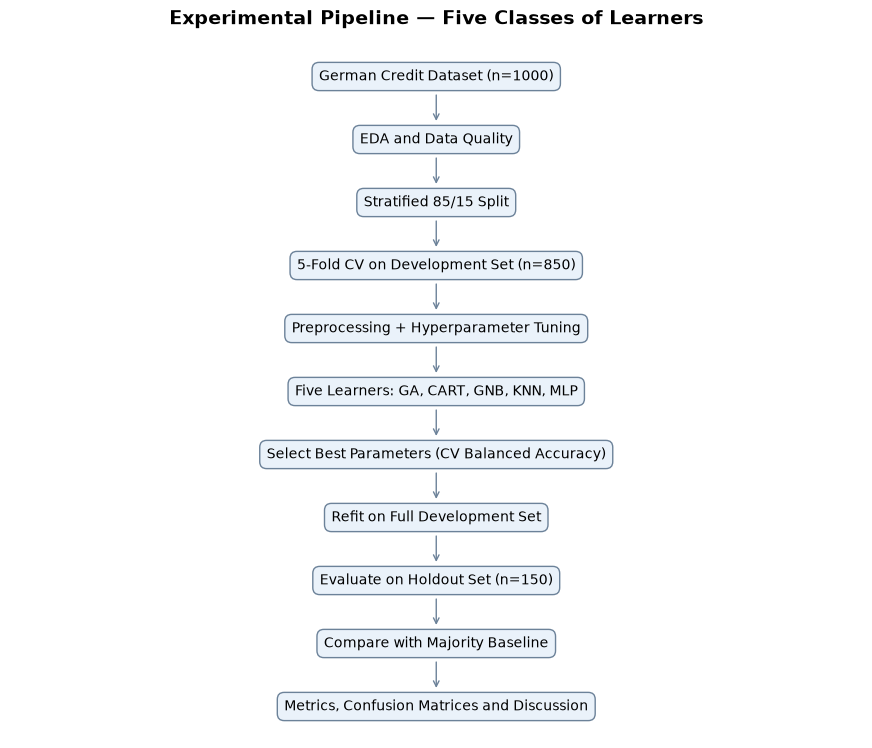

In [1]:
import sys
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(
    0,
    str(PROJECT_ROOT / "src" / "code")
)
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

steps = [
    "German Credit Dataset (n=1000)",
    "EDA and Data Quality",
    "Stratified 85/15 Split",
    "5-Fold CV on Development Set (n=850)",
    "Preprocessing + Hyperparameter Tuning",
    "Five Learners: GA, CART, GNB, KNN, MLP",
    "Select Best Parameters (CV Balanced Accuracy)",
    "Refit on Full Development Set",
    "Evaluate on Holdout Set (n=150)",
    "Compare with Majority Baseline",
    "Metrics, Confusion Matrices and Discussion"
]

fig, ax = plt.subplots(figsize=(11, 9))
ax.set_xlim(0, 10)
ax.set_ylim(-0.5, len(steps) - 0.5)
ax.axis("off")

for i, step in enumerate(steps):
    y = len(steps) - 1 - i

    ax.text(
        5, y, step,
        ha="center", va="center", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.5", fc="#eaf2fa", ec="#6c8299")
    )

    if i < len(steps) - 1:
        ax.annotate(
            "", xy=(5, y - 0.75), xytext=(5, y - 0.25),
            arrowprops=dict(arrowstyle="->", color="#6c8299")
        )

ax.set_title("Experimental Pipeline — Five Classes of Learners",
             fontsize=14, fontweight="bold", pad=15)
plt.savefig(FIGURES_DIR / "experimental_pipeline.png", dpi=200, bbox_inches="tight")
plt.show()

In [2]:
# import sys

# PROJECT_ROOT = Path.cwd().resolve()
# if PROJECT_ROOT.name == "notebooks":
#     PROJECT_ROOT = PROJECT_ROOT.parent

# sys.path.insert(
#     0,
#     str(PROJECT_ROOT / "src" / "code")
# )

from evolutionaries import EvolutionaryClassifier
from symbolists import SymbolistClassifier
from bayesians import BayesianClassifier
from analogizers import AnalogizerClassifier
from connectionists import ConnectionistClassifier
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier

SEED = 42
TEST_SIZE = 0.15
TRAINING_FOLDS = 5
DATA_PATH = Path('datasets/german_credit.csv.zst')
if not DATA_PATH.exists():
    DATA_PATH = Path('../datasets/german_credit.csv.zst')
if not DATA_PATH.exists():
    raise FileNotFoundError('Put german_credit.csv.zst under datasets/ (or ../datasets/).')
BEST_PARAMS = {
    "Evolutionaries": {},
    "Symbolists": {},
    "Bayesians": {},
    "Connectionists": {},
    "Analogizers": {}
}

### Evolutionaries — Decision Threshold Sensitivity Analysis

The Evolutionary classifier is examined across different decision thresholds to investigate the trade-off between detecting high-risk applicants and incorrectly rejecting creditworthy applicants.

Out-of-fold predictions from stratified 5-fold cross-validation on the development set are used to avoid optimizing the threshold on the final holdout.

We examine Recall (Bad), Precision (Bad), Balanced Accuracy, and a cost-sensitive metric assuming that accepting a bad applicant is five times more costly than rejecting a good applicant.

The 5:1 cost ratio is treated as an experimental assumption for sensitivity analysis.

## 1. Load and Inspect Data

The German Credit dataset contains **1,000 observations**, **20 input features**, and a binary target variable (`class`) representing credit risk.

The target distribution is imbalanced:
- **Good credit:** 700 observations (70%)
- **Bad credit:** 300 observations (30%)

This imbalance motivates the use of **Balanced Accuracy** as the primary model-selection metric.

This section verifies the dataset structure and target distribution. Feature exploration and preprocessing decisions are performed using the development set to preserve the independence of the holdout evaluation.

In [3]:
df = pl.read_csv(DATA_PATH).to_pandas()
assert 'class' in df.columns, 'Expected target column: class'
print('Shape:', df.shape)
print('Target counts:', df['class'].value_counts().to_dict())
display(df.head(3).iloc[:, :8])

Shape: (1000, 21)
Target counts: {'good': 700, 'bad': 300}


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment
0,<0,6.0,critical/other existing credit,radio/tv,1169.0,no known savings,>=7,4.0
1,0<=X<200,48.0,existing paid,radio/tv,5951.0,<100,1<=X<4,2.0
2,no checking,12.0,critical/other existing credit,education,2096.0,<100,4<=X<7,2.0


## 2. Stratified Development/Test Split

The dataset is divided into **85% development data (850 observations)** and **15% holdout test data (150 observations)** using stratified sampling to preserve the original class distribution.

The development set is used for manual hyperparameter exploration, systematic grid search, and stratified 5-fold cross-validation. The same split is shared across all five learners to ensure consistent comparisons.

The holdout set is excluded from model fitting, preprocessing estimation, and hyperparameter optimization.

The target variable is encoded as **0 = bad credit** and **1 = good credit**. This mapping is retained consistently throughout the evaluation, particularly when calculating precision, recall, and F1-score for high-risk applicants.

In [4]:

X = df.drop(columns="class")

label_encoder = LabelEncoder()
y = pd.Series(
    label_encoder.fit_transform(df["class"]),
    index=df.index,
    name="class"
)

X_train, X_final_test, y_train, y_final_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=SEED
)

target_mapping = {
    label: int(code)
    for code, label in enumerate(label_encoder.classes_)
}

print(f"Development set: {len(X_train)} observations")
print(f"Holdout test set: {len(X_final_test)} observations")
print(f"Target mapping: {target_mapping}")
print(
    "Development class distribution:",
    y_train.value_counts(normalize=True).sort_index().round(3).to_dict()
)

Development set: 850 observations
Holdout test set: 150 observations
Target mapping: {'bad': 0, 'good': 1}
Development class distribution: {0: 0.3, 1: 0.7}


## 3. Exploratory Data Analysis (Development Set Only)

Exploratory analysis is performed exclusively on the development set to avoid using holdout observations for data-driven decisions.

The analysis examines:

- **Class balance:** the proportion of good and bad credit applicants.
- **Data quality:** missing values and feature types.
- **Numerical feature distributions:** variability, skewness, and potential outliers.
- **Feature–target relationships:** differences between good and bad credit applicants.

These characteristics help explain the expected behavior of the five learning paradigms and motivate the preprocessing strategy.

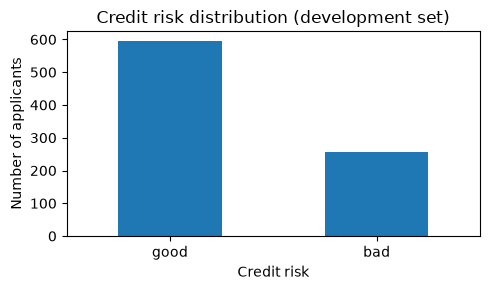

Missing values: 0
Numerical features: 7
Categorical features: 13


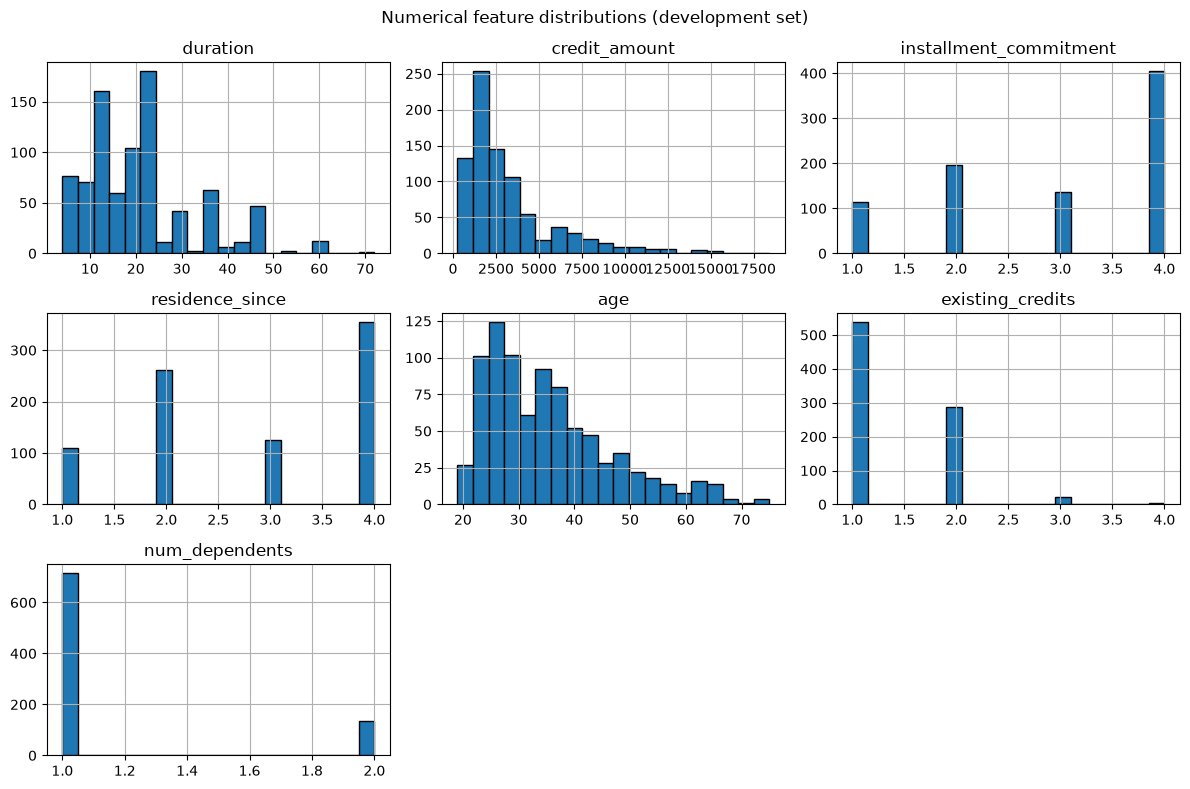

In [5]:

# Class distribution
class_counts = y_train.map(
    dict(enumerate(label_encoder.classes_))
).value_counts()

fig, ax = plt.subplots(figsize=(5, 3))
class_counts.reindex(["good", "bad"]).plot.bar(ax=ax)
ax.set(
    title="Credit risk distribution (development set)",
    xlabel="Credit risk",
    ylabel="Number of applicants"
)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "target_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

# Data quality
missing = X_train.isna().sum()
print(f"Missing values: {missing.sum()}")
print(f"Numerical features: {X_train.select_dtypes(include='number').shape[1]}")
print(f"Categorical features: {X_train.select_dtypes(exclude='number').shape[1]}")

# Numerical feature distributions
numeric_cols = X_train.select_dtypes(include="number").columns

X_train[numeric_cols].hist(
    bins=20,
    figsize=(12, 8),
    edgecolor="black"
)
plt.suptitle("Numerical feature distributions (development set)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "numeric_distributions.png", dpi=200, bbox_inches="tight")
plt.show()


### EDA Observations

The development set preserves the original class imbalance, with approximately **70% good** and **30% bad** credit applicants. Consequently, accuracy alone may favor models that primarily predict the majority class.

The missing-value check identifies whether imputation is necessary. Numerical feature distributions are inspected for differences in scale, skewness, and extreme values, which may particularly affect distance-based and gradient-based learners.

These observations motivate consistent preprocessing and the use of Balanced Accuracy for model comparison.

### Numeric Feature Correlations and Target Relationships

Pearson correlation is used to examine linear relationships between numerical features and their associations with credit-risk classification.

The first visualization identifies potential dependencies between numerical predictors. The second examines their individual linear relationships with the binary target (Bad = 0, Good = 1).

These correlations are exploratory and do not imply causation. Weak individual correlations do not exclude nonlinear relationships or interactions that may be captured by the five learning paradigms.

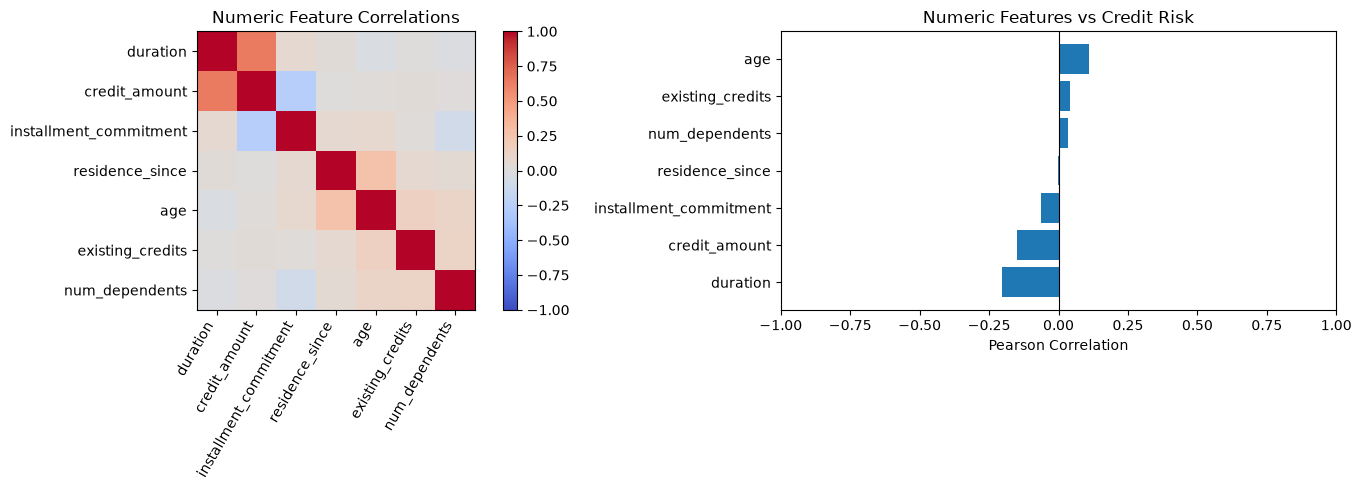

In [6]:
# EDA — Numeric correlations and relationships with target

corr = X_train[numeric_cols].corr()

# Target encoding: Bad = 0, Good = 1
target_numeric = pd.Series(
    label_encoder.transform(["bad"])[0] == y_train,
    index=y_train.index
).astype(int)

target_corr = X_train[numeric_cols].corrwith(target_numeric)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Numeric feature correlations
im = axes[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(numeric_cols)))
axes[0].set_yticks(range(len(numeric_cols)))
axes[0].set_xticklabels(numeric_cols, rotation=60, ha="right")
axes[0].set_yticklabels(numeric_cols)
axes[0].set_title("Numeric Feature Correlations")
fig.colorbar(im, ax=axes[0])

# Numeric features vs target (Bad = 0, Good = 1)
target_corr = X_train[numeric_cols].corrwith(
    pd.Series(y_train, index=X_train.index)
).sort_values()

axes[1].barh(target_corr.index, target_corr.values)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlim(-1, 1)
axes[1].set_xlabel("Pearson Correlation")
axes[1].set_title("Numeric Features vs Credit Risk")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "numeric_correlations.png", dpi=200, bbox_inches="tight")
plt.show()

**EDA Findings**

The strongest positive correlation between numerical predictors is observed between credit duration and credit amount, suggesting that larger loans tend to have longer repayment periods.

Credit duration and credit amount show the strongest negative associations with the target (Good = 1), indicating that longer and larger loans are associated with higher credit risk. Age shows a weaker positive association with good credit outcomes.

Most other numerical features have relatively weak linear correlations with the target. This suggests that individual linear relationships alone may not fully explain credit risk, motivating the comparison of different learning paradigms.

## 4. Shared Fold-Safe Preprocessing

All five learners use a common preprocessing strategy to ensure consistent experimental conditions.

- **Numerical features:** median imputation followed by standard scaling.
- **Categorical features:** most-frequent imputation followed by one-hot encoding, with unknown categories ignored.
- **Cross-validation:** identical stratified 5-fold splits are used for every learner (680 training and 170 validation observations per fold).
- **Leakage prevention:** preprocessing parameters are estimated exclusively from each fold's training partition and applied to its validation partition.
- **Feature selection:** no additional feature selection is performed, allowing all learners to operate on the same input information.

The shared preprocessing strategy prioritizes comparability across learning paradigms rather than optimizing preprocessing separately for each model.

In [7]:

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            drop="first"
        ))
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_cols),
            ("categorical", categorical_pipeline, categorical_cols)
        ],
        remainder="drop",
        sparse_threshold=0
    )

cv = StratifiedKFold(
    n_splits=TRAINING_FOLDS,
    shuffle=True,
    random_state=SEED
)

folds = list(cv.split(X_train, y_train))

for i, (train_idx, val_idx) in enumerate(folds, 1):
    print(
        f"Fold {i}: "
        f"train={len(train_idx)}, "
        f"validation={len(val_idx)}"
    )


Fold 1: train=680, validation=170
Fold 2: train=680, validation=170
Fold 3: train=680, validation=170
Fold 4: train=680, validation=170
Fold 5: train=680, validation=170


## 5. Shared Evaluation Metrics and Majority-Class Baseline

All learners are evaluated using identical stratified 5-fold cross-validation splits and fold-specific preprocessing.

**Balanced Accuracy** is the primary selection metric because the dataset contains unequal class proportions (70% good, 30% bad). Standard Accuracy is reported as a complementary measure.

A majority-class DummyClassifier provides a reference point. Since it always predicts the most frequent class, it achieves approximately 70% Accuracy but only 50% Balanced Accuracy.

Cross-validation results are summarized using the mean and standard deviation across the five folds. Hyperparameter optimization for each learning paradigm is performed in subsequent sections.

In [8]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score

def evaluate_learner(name, estimator):
    balanced_scores = []
    accuracy_scores = []

    for train_idx, val_idx in folds:
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        preprocessor = make_preprocessor()
        X_tr = preprocessor.fit_transform(X_fold_train)
        X_val = preprocessor.transform(X_fold_val)

        model = clone(estimator)
        model.fit(X_tr, y_fold_train)
        predictions = model.predict(X_val)

        balanced_scores.append(
            balanced_accuracy_score(y_fold_val, predictions)
        )
        accuracy_scores.append(
            accuracy_score(y_fold_val, predictions)
        )

    return {
        "learner": name,
        "balanced_accuracy_mean": np.mean(balanced_scores),
        "balanced_accuracy_std": np.std(balanced_scores, ddof=1),
        "accuracy_mean": np.mean(accuracy_scores),
        "accuracy_std": np.std(accuracy_scores, ddof=1)
    }

baseline_result = evaluate_learner(
    "Baseline (majority)",
    DummyClassifier(strategy="most_frequent")
)

print(pd.DataFrame([baseline_result]).round(4).to_string(index=False))


            learner  balanced_accuracy_mean  balanced_accuracy_std  accuracy_mean  accuracy_std
Baseline (majority)                     0.5                    0.0            0.7           0.0


## 6. Evolutionaries — Genetic Algorithm

The `EvolutionaryClassifier` uses a genetic algorithm (`pyBlindOpt.ga.genetic_algorithm`) to optimize the coefficients and bias of a linear classifier using weighted binary log-loss.

Hyperparameters are evaluated using **stratified 5-fold cross-validation**, with Balanced Accuracy as the primary selection metric.

The grid search explores:

- **Generations (`n_iter`):** 200, 300
- **Population size (`n_pop`):** 40, 80
- **Weight bounds (`weight_bound`):** 2.0, 3.0
- **Bias bounds (`bias_bound`):** 2.5, 5.0

The class weight (`class_0_weight=5.0`) remains fixed to assign a higher penalty to misclassifying Bad Credit applicants (class 0).

The search evaluates **16 configurations across 5 folds (80 model fits)**. Preprocessing is fitted separately within each training fold and reused across configurations for efficiency.

Both predictive performance and training time are recorded to examine the trade-off between optimization quality and computational cost.

In [9]:

from itertools import product
from time import perf_counter
from sklearn.metrics import balanced_accuracy_score
import pandas as pd
import numpy as np

# Hyperparameter search space
param_grid = {
    "n_iter": [200, 300],
    "n_pop": [40, 80],
    "weight_bound": [2.0, 3.0],
    "bias_bound": [2.5, 5.0],
}

# Prepare CV folds once to avoid repeated preprocessing
prepared_folds = []

for train_idx, val_idx in folds:
    preprocessor = make_preprocessor()

    X_tr = preprocessor.fit_transform(
        X_train.iloc[train_idx]
    )
    X_val = preprocessor.transform(
        X_train.iloc[val_idx]
    )

    prepared_folds.append((
        X_tr,
        y_train.iloc[train_idx].to_numpy(),
        X_val,
        y_train.iloc[val_idx].to_numpy()
    ))

# Generate all hyperparameter combinations
combinations = list(product(
    param_grid["n_iter"],
    param_grid["n_pop"],
    param_grid["weight_bound"],
    param_grid["bias_bound"]
))

tuning_results = []
total_start = perf_counter()

for i, (n_iter, n_pop, weight_bound, bias_bound) in enumerate(
    combinations, start=1
):
    scores = []
    times = []

    for X_tr, y_tr, X_val, y_val in prepared_folds:
        model = EvolutionaryClassifier(
            n_iter=n_iter,
            n_pop=n_pop,
            weight_bound=weight_bound,
            bias_bound=bias_bound,
            class_0_weight=5.0,
            random_state=SEED
        )

        start = perf_counter()
        model.fit(X_tr, y_tr)
        times.append(perf_counter() - start)

        predictions = model.predict(X_val)

        scores.append(
            balanced_accuracy_score(y_val, predictions)
        )

    tuning_results.append({
        "n_iter": n_iter,
        "n_pop": n_pop,
        "weight_bound": weight_bound,
        "bias_bound": bias_bound,
        "mean_balanced_accuracy": np.mean(scores),
        "std_balanced_accuracy": np.std(scores, ddof=1),
        "mean_fit_time": np.mean(times),
        "total_fit_time": np.sum(times)
    })

    print(
        f"[{i}/{len(combinations)}] "
        f"iter={n_iter}, pop={n_pop}, "
        f"weight_bound={weight_bound}, bias_bound={bias_bound} "
        f"| BA={np.mean(scores):.4f} "
        f"| elapsed={perf_counter()-total_start:.1f}s",
        flush=True
    )

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "mean_balanced_accuracy",
    ascending=False
).reset_index(drop=True)

print(
    f"\nTotal search time: "
    f"{perf_counter()-total_start:.1f}s"
)

display(tuning_df.head(10))

best_row = tuning_df.iloc[0]

best_params = {
    "n_iter": int(best_row["n_iter"]),
    "n_pop": int(best_row["n_pop"]),
    "weight_bound": float(best_row["weight_bound"]),
    "bias_bound": float(best_row["bias_bound"]),
}

print("Best parameters:", best_params)
print(
    "Best CV Balanced Accuracy:",
    round(best_row["mean_balanced_accuracy"], 4)
)

[1/16] iter=200, pop=40, weight_bound=2.0, bias_bound=2.5 | BA=0.6880 | elapsed=2.0s
[2/16] iter=200, pop=40, weight_bound=2.0, bias_bound=5.0 | BA=0.7048 | elapsed=3.6s
[3/16] iter=200, pop=40, weight_bound=3.0, bias_bound=2.5 | BA=0.6978 | elapsed=5.2s
[4/16] iter=200, pop=40, weight_bound=3.0, bias_bound=5.0 | BA=0.6933 | elapsed=6.9s
[5/16] iter=200, pop=80, weight_bound=2.0, bias_bound=2.5 | BA=0.7120 | elapsed=10.1s
[6/16] iter=200, pop=80, weight_bound=2.0, bias_bound=5.0 | BA=0.7034 | elapsed=13.4s
[7/16] iter=200, pop=80, weight_bound=3.0, bias_bound=2.5 | BA=0.7078 | elapsed=16.6s
[8/16] iter=200, pop=80, weight_bound=3.0, bias_bound=5.0 | BA=0.7000 | elapsed=19.8s
[9/16] iter=300, pop=40, weight_bound=2.0, bias_bound=2.5 | BA=0.6947 | elapsed=22.0s
[10/16] iter=300, pop=40, weight_bound=2.0, bias_bound=5.0 | BA=0.7020 | elapsed=24.4s
[11/16] iter=300, pop=40, weight_bound=3.0, bias_bound=2.5 | BA=0.6983 | elapsed=26.7s
[12/16] iter=300, pop=40, weight_bound=3.0, bias_bound=5

,n_iter,n_pop,weight_bound,bias_bound,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,total_fit_time
0,200,80,2.0,2.5,0.712045,0.030710,0.648097,3.240483
1,300,80,2.0,5.0,0.710924,0.038618,0.962088,4.810442
2,300,80,2.0,2.5,0.708683,0.034831,0.920790,4.603949
3,200,80,3.0,2.5,0.707843,0.033505,0.645598,3.227991
4,200,40,2.0,5.0,0.704762,0.025814,0.311249,1.556247
5,300,80,3.0,2.5,0.704202,0.034865,0.961927,4.809637
6,200,80,2.0,5.0,0.703361,0.031230,0.661768,3.308842
7,300,80,3.0,5.0,0.703361,0.042785,0.960295,4.801476
8,300,40,2.0,5.0,0.701961,0.022614,0.467085,2.335426
9,200,80,3.0,5.0,0.700000,0.037495,0.623026,3.115130


Best parameters: {'n_iter': 200, 'n_pop': 80, 'weight_bound': 2.0, 'bias_bound': 2.5}
Best CV Balanced Accuracy: 0.712


### Evolutionary Hyperparameter Sensitivity and Computational Cost

The plots illustrate the effects of generations, population size, weight bounds, and bias bounds on cross-validation Balanced Accuracy and training time.

Larger populations generally improve performance but increase computational cost. Increasing the number of generations provides limited additional benefit relative to the extra training time. The interaction between weight and bias bounds indicates that their effects are not independent.

The best individual configuration achieves **0.7120 Balanced Accuracy** with 200 generations, a population of 80, `weight_bound=2.0`, and `bias_bound=2.5`.

The analysis highlights the trade-off between predictive performance and computational efficiency. Results are based on a limited hyperparameter grid and a fixed random seed.

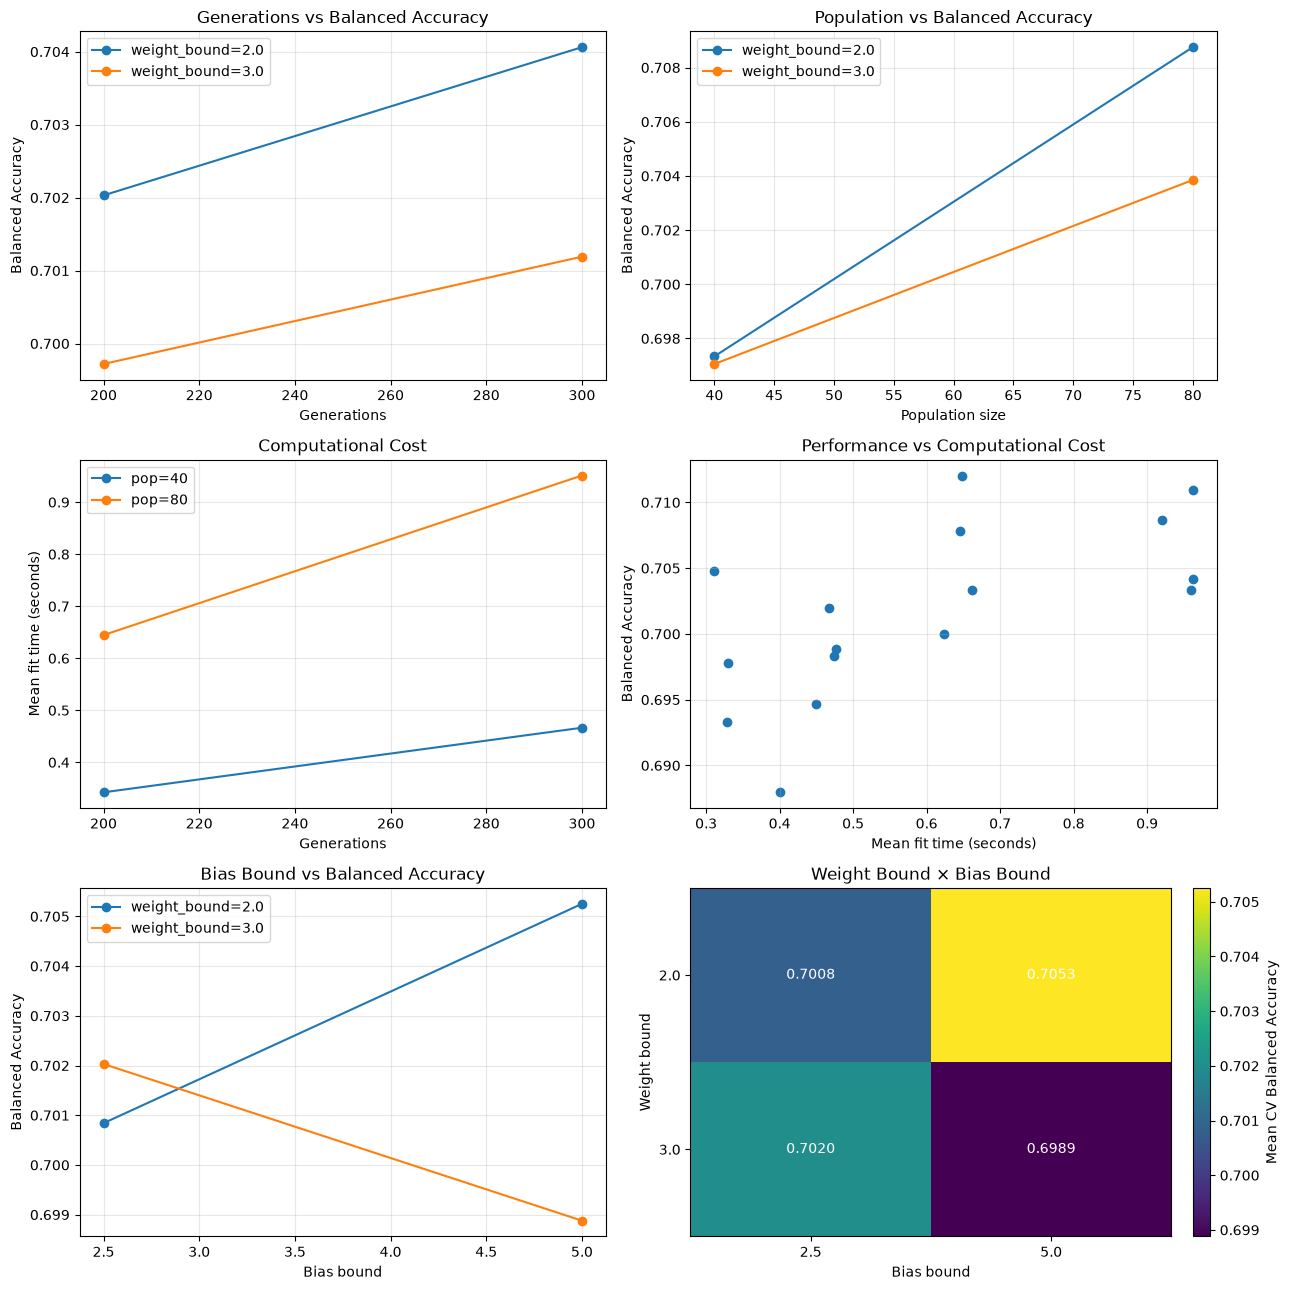

In [10]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(13, 13))

# 1. Generations vs Balanced Accuracy
for bound in sorted(tuning_df["weight_bound"].unique()):
    subset = tuning_df[tuning_df["weight_bound"] == bound]
    summary = subset.groupby("n_iter")[
        "mean_balanced_accuracy"
    ].mean()

    axes[0, 0].plot(
        summary.index, summary.values,
        marker="o", label=f"weight_bound={bound}"
    )

axes[0, 0].set_title("Generations vs Balanced Accuracy")
axes[0, 0].set_xlabel("Generations")
axes[0, 0].set_ylabel("Balanced Accuracy")
axes[0, 0].legend()

# 2. Population vs Balanced Accuracy
for bound in sorted(tuning_df["weight_bound"].unique()):
    subset = tuning_df[tuning_df["weight_bound"] == bound]
    summary = subset.groupby("n_pop")[
        "mean_balanced_accuracy"
    ].mean()

    axes[0, 1].plot(
        summary.index, summary.values,
        marker="o", label=f"weight_bound={bound}"
    )

axes[0, 1].set_title("Population vs Balanced Accuracy")
axes[0, 1].set_xlabel("Population size")
axes[0, 1].set_ylabel("Balanced Accuracy")
axes[0, 1].legend()

# 3. Training time vs generations
for pop in sorted(tuning_df["n_pop"].unique()):
    subset = tuning_df[tuning_df["n_pop"] == pop]
    summary = subset.groupby("n_iter")[
        "mean_fit_time"
    ].mean()

    axes[1, 0].plot(
        summary.index, summary.values,
        marker="o", label=f"pop={pop}"
    )

axes[1, 0].set_title("Computational Cost")
axes[1, 0].set_xlabel("Generations")
axes[1, 0].set_ylabel("Mean fit time (seconds)")
axes[1, 0].legend()

# 4. Accuracy vs computational cost
axes[1, 1].scatter(
    tuning_df["mean_fit_time"],
    tuning_df["mean_balanced_accuracy"]
)

axes[1, 1].set_title("Performance vs Computational Cost")
axes[1, 1].set_xlabel("Mean fit time (seconds)")
axes[1, 1].set_ylabel("Balanced Accuracy")

# 5. Bias bound vs Balanced Accuracy
for weight_bound in sorted(tuning_df["weight_bound"].unique()):
    subset = tuning_df[
        tuning_df["weight_bound"] == weight_bound
    ]
    summary = subset.groupby("bias_bound")[
        "mean_balanced_accuracy"
    ].mean()

    axes[2, 0].plot(
        summary.index, summary.values,
        marker="o", label=f"weight_bound={weight_bound}"
    )

axes[2, 0].set_title("Bias Bound vs Balanced Accuracy")
axes[2, 0].set_xlabel("Bias bound")
axes[2, 0].set_ylabel("Balanced Accuracy")
axes[2, 0].legend()

# 6. Interaction between weight and bias bounds
interaction = tuning_df.pivot_table(
    index="weight_bound",
    columns="bias_bound",
    values="mean_balanced_accuracy",
    aggfunc="mean"
)

im = axes[2, 1].imshow(
    interaction.values,
    aspect="auto",
    cmap="viridis"
)

axes[2, 1].set_xticks(range(len(interaction.columns)))
axes[2, 1].set_xticklabels(interaction.columns)
axes[2, 1].set_yticks(range(len(interaction.index)))
axes[2, 1].set_yticklabels(interaction.index)

axes[2, 1].set_title("Weight Bound × Bias Bound")
axes[2, 1].set_xlabel("Bias bound")
axes[2, 1].set_ylabel("Weight bound")

for i in range(len(interaction.index)):
    for j in range(len(interaction.columns)):
        axes[2, 1].text(
            j, i,
            f"{interaction.iloc[i, j]:.4f}",
            ha="center",
            va="center",
            color="white"
        )

fig.colorbar(
    im,
    ax=axes[2, 1],
    label="Mean CV Balanced Accuracy",
    fraction=0.046,
    pad=0.04
)

for ax in axes.flat[:5]:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:
display(
    tuning_df[
        [
            "n_iter",
            "n_pop",
            "weight_bound",
            "bias_bound",
            "mean_balanced_accuracy",
            "std_balanced_accuracy",
            "mean_fit_time"
        ]
    ].head(16).round(4)
)

,n_iter,n_pop,weight_bound,bias_bound,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time
0,200,80,2.0,2.5,0.7120,0.0307,0.6481
1,300,80,2.0,5.0,0.7109,0.0386,0.9621
2,300,80,2.0,2.5,0.7087,0.0348,0.9208
3,200,80,3.0,2.5,0.7078,0.0335,0.6456
4,200,40,2.0,5.0,0.7048,0.0258,0.3112
5,300,80,3.0,2.5,0.7042,0.0349,0.9619
6,200,80,2.0,5.0,0.7034,0.0312,0.6618
7,300,80,3.0,5.0,0.7034,0.0428,0.9603
8,300,40,2.0,5.0,0.7020,0.0226,0.4671
9,200,80,3.0,5.0,0.7000,0.0375,0.6230


In [12]:
best_row = tuning_df.iloc[0]

BEST_PARAMS["Evolutionaries"] = {
    "n_iter": int(best_row["n_iter"]),
    "n_pop": int(best_row["n_pop"]),
    "weight_bound": float(best_row["weight_bound"]),
    "bias_bound": float(best_row["bias_bound"]),
    "class_0_weight": 5.0,
    "random_state": SEED
}

print("Selected Evolutionary parameters:")
print(BEST_PARAMS["Evolutionaries"])

print(
    f"CV Balanced Accuracy: "
    f"{best_row['mean_balanced_accuracy']:.4f} "
    f"± {best_row['std_balanced_accuracy']:.4f}"
)

Selected Evolutionary parameters:
{'n_iter': 200, 'n_pop': 80, 'weight_bound': 2.0, 'bias_bound': 2.5, 'class_0_weight': 5.0, 'random_state': 42}
CV Balanced Accuracy: 0.7120 ± 0.0307


### Evolutionary Hyperparameter Selection

The best configuration achieved a mean cross-validation Balanced Accuracy of **0.7120 ± 0.0307**, using 200 generations, a population of 80, a weight bound of 2.0, and a bias bound of 2.5.

Increasing the number of generations did not improve the best observed performance and increased computational cost. The selected configuration therefore provides the highest observed Balanced Accuracy within the evaluated search space while maintaining a relatively low training time.

## 7. Symbolists — Decision Tree (CART)

The Symbolist approach uses a Decision Tree (CART) to classify credit applicants through interpretable decision rules. Splits are selected using Gini impurity.

Hyperparameters are optimized using **stratified 5-fold cross-validation**, with Balanced Accuracy as the primary selection metric.

The grid search explores:

- **Maximum tree depth (`max_depth`):** 3, 5, 8, 12, 16, None
- **Minimum samples per leaf (`min_samples_leaf`):** 1, 3, 5, 10, 20
- **Pruning strength (`ccp_alpha`):** 0, 0.001, 0.005, 0.01

The splitting criterion (`gini`) and minimum samples required to split a node (`min_samples_split=2`) remain fixed.

The search evaluates **120 configurations across 5 folds (600 model fits)**. Training time and cross-validation performance are recorded to analyze model complexity, overfitting control, and computational efficiency.

In [13]:

from itertools import product
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# Hyperparameter search space
symbolist_param_grid = {
    "max_depth": [3, 5, 8, 12, 16, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
    "ccp_alpha": [0.0, 0.001, 0.005, 0.01],
}

# Reuse preprocessed CV folds from Evolutionaries.
# Each preprocessor was fitted only on its training fold.

combinations = list(product(
    symbolist_param_grid["max_depth"],
    symbolist_param_grid["min_samples_leaf"],
    symbolist_param_grid["ccp_alpha"]
))

symbolist_tuning_results = []
total_start = perf_counter()

for i, (max_depth, min_samples_leaf, ccp_alpha) in enumerate(
    combinations, start=1
):
    scores = []
    times = []

    for X_tr, y_tr, X_val, y_val in prepared_folds:
        model = SymbolistClassifier(
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            min_samples_split=2,
            criterion="gini",
            ccp_alpha=ccp_alpha,
            random_state=SEED
        )

        start = perf_counter()
        model.fit(X_tr, y_tr)
        times.append(perf_counter() - start)

        predictions = model.predict(X_val)

        scores.append(
            balanced_accuracy_score(y_val, predictions)
        )

    symbolist_tuning_results.append({
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "ccp_alpha": ccp_alpha,
        "mean_balanced_accuracy": np.mean(scores),
        "std_balanced_accuracy": np.std(scores, ddof=1),
        "mean_fit_time": np.mean(times),
        "total_fit_time": np.sum(times)
    })

    if i % 20 == 0 or i == len(combinations):
        print(
            f"[{i}/{len(combinations)}] "
            f"elapsed={perf_counter()-total_start:.1f}s",
            flush=True
        )

symbolist_tuning_df = (
    pd.DataFrame(symbolist_tuning_results)
    .sort_values(
        "mean_balanced_accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"\nTotal Symbolist search time: "
    f"{perf_counter()-total_start:.1f}s"
)

display(symbolist_tuning_df.head(15))


[20/120] elapsed=0.1s
[40/120] elapsed=0.3s
[60/120] elapsed=0.4s
[80/120] elapsed=0.6s
[100/120] elapsed=0.8s
[120/120] elapsed=1.0s

Total Symbolist search time: 1.0s


,max_depth,min_samples_leaf,ccp_alpha,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,total_fit_time
0,12.0,1,0.000,0.666387,0.032642,0.001817,0.009084
1,12.0,1,0.001,0.664426,0.032810,0.001867,0.009334
2,NaN,1,0.000,0.661625,0.029355,0.001848,0.009241
3,NaN,1,0.001,0.659664,0.026940,0.001834,0.009169
4,16.0,1,0.000,0.656303,0.039732,0.001919,0.009596
5,8.0,20,0.000,0.654902,0.044857,0.001190,0.005949
6,16.0,1,0.001,0.654342,0.037364,0.001887,0.009434
7,8.0,20,0.001,0.653221,0.046468,0.001227,0.006135
8,12.0,20,0.000,0.648739,0.046138,0.001171,0.005853
9,16.0,20,0.000,0.648739,0.046138,0.001131,0.005654


### Symbolist Hyperparameter Sensitivity Analysis

The results show that tree complexity and pruning strength influence classification performance. Balanced Accuracy generally improves with increasing tree depth up to approximately 12 levels, while stronger pruning (`ccp_alpha=0.01`) substantially reduces performance, suggesting underfitting.

The effect of minimum leaf size is non-monotonic, indicating that stronger regularization does not consistently improve generalization.

The best configuration achieves **0.6664 ± 0.0326** cross-validation Balanced Accuracy with `max_depth=12`, `min_samples_leaf=1`, and `ccp_alpha=0.0`.

Training remains computationally inexpensive across all evaluated configurations. The results suggest that moderate pruning can be tolerated, but excessive pruning removes useful decision structure.

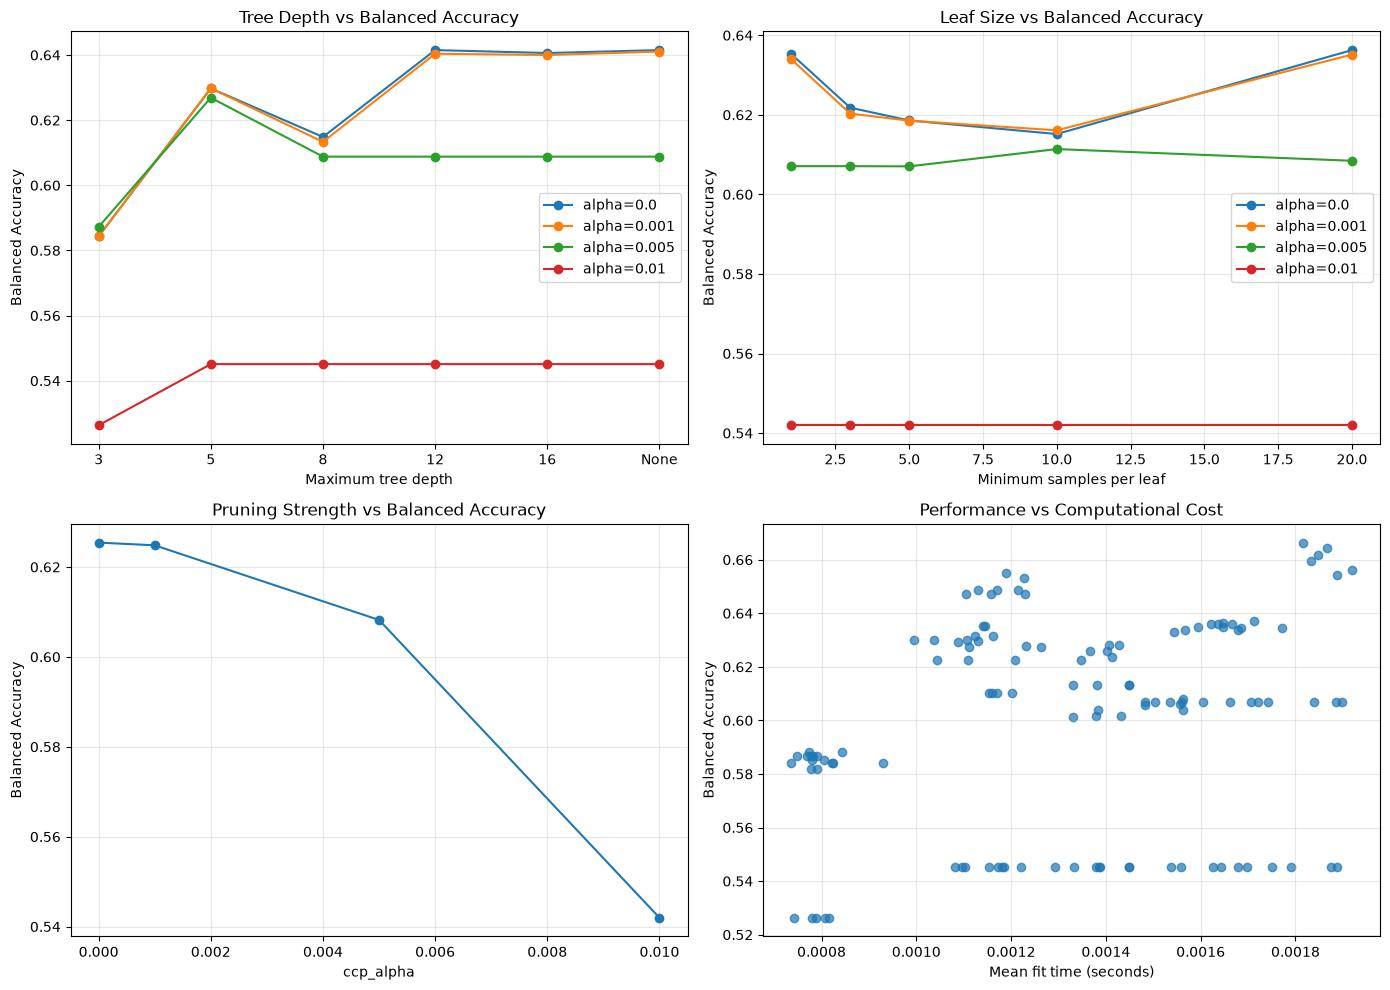

In [14]:
import matplotlib.pyplot as plt

df = symbolist_tuning_df.copy()
df["depth_label"] = df["max_depth"].apply(
    lambda x: "None" if pd.isna(x) else str(int(x))
)

depth_order = ["3", "5", "8", "12", "16", "None"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Tree depth vs Balanced Accuracy
for alpha in sorted(df["ccp_alpha"].unique()):
    subset = df[df["ccp_alpha"] == alpha]
    grouped = subset.groupby("depth_label")["mean_balanced_accuracy"].mean()
    axes[0, 0].plot(
        depth_order,
        grouped.reindex(depth_order),
        marker="o",
        label=f"alpha={alpha}"
    )

axes[0, 0].set_title("Tree Depth vs Balanced Accuracy")
axes[0, 0].set_xlabel("Maximum tree depth")
axes[0, 0].set_ylabel("Balanced Accuracy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Minimum leaf size vs Balanced Accuracy
for alpha in sorted(df["ccp_alpha"].unique()):
    subset = df[df["ccp_alpha"] == alpha]
    grouped = subset.groupby("min_samples_leaf")["mean_balanced_accuracy"].mean()
    axes[0, 1].plot(
        grouped.index,
        grouped.values,
        marker="o",
        label=f"alpha={alpha}"
    )

axes[0, 1].set_title("Leaf Size vs Balanced Accuracy")
axes[0, 1].set_xlabel("Minimum samples per leaf")
axes[0, 1].set_ylabel("Balanced Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Pruning strength vs Balanced Accuracy
grouped = df.groupby("ccp_alpha")["mean_balanced_accuracy"].mean()

axes[1, 0].plot(grouped.index, grouped.values, marker="o")
axes[1, 0].set_title("Pruning Strength vs Balanced Accuracy")
axes[1, 0].set_xlabel("ccp_alpha")
axes[1, 0].set_ylabel("Balanced Accuracy")
axes[1, 0].grid(alpha=0.3)

# 4. Performance vs computational cost
axes[1, 1].scatter(
    df["mean_fit_time"],
    df["mean_balanced_accuracy"],
    alpha=0.7
)

axes[1, 1].set_title("Performance vs Computational Cost")
axes[1, 1].set_xlabel("Mean fit time (seconds)")
axes[1, 1].set_ylabel("Balanced Accuracy")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [15]:
display(symbolist_tuning_df.head(15))

,max_depth,min_samples_leaf,ccp_alpha,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,total_fit_time
0,12.0,1,0.000,0.666387,0.032642,0.001817,0.009084
1,12.0,1,0.001,0.664426,0.032810,0.001867,0.009334
2,NaN,1,0.000,0.661625,0.029355,0.001848,0.009241
3,NaN,1,0.001,0.659664,0.026940,0.001834,0.009169
4,16.0,1,0.000,0.656303,0.039732,0.001919,0.009596
5,8.0,20,0.000,0.654902,0.044857,0.001190,0.005949
6,16.0,1,0.001,0.654342,0.037364,0.001887,0.009434
7,8.0,20,0.001,0.653221,0.046468,0.001227,0.006135
8,12.0,20,0.000,0.648739,0.046138,0.001171,0.005853
9,16.0,20,0.000,0.648739,0.046138,0.001131,0.005654


In [16]:
best_row = symbolist_tuning_df.iloc[0]

BEST_PARAMS["Symbolists"] = {
    "max_depth": (
        None if pd.isna(best_row["max_depth"])
        else int(best_row["max_depth"])
    ),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
    "min_samples_split": 2,
    "criterion": "gini",
    "ccp_alpha": float(best_row["ccp_alpha"]),
    "random_state": SEED
}

print("Selected Symbolist parameters:")
print(BEST_PARAMS["Symbolists"])

print(
    f"CV Balanced Accuracy: "
    f"{best_row['mean_balanced_accuracy']:.4f} "
    f"± {best_row['std_balanced_accuracy']:.4f}"
)

Selected Symbolist parameters:
{'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 2, 'criterion': 'gini', 'ccp_alpha': 0.0, 'random_state': 42}
CV Balanced Accuracy: 0.6664 ± 0.0326


### Decision Tree — Validation Curve

The validation curve examines how tree complexity affects training and validation performance.

Shallow trees may underfit the data, resulting in low Balanced Accuracy on both training and validation sets. As maximum depth increases, training performance generally improves, but validation performance may plateau or decrease, indicating overfitting.

The gap between training and validation scores illustrates the model's generalization behavior. Error bars represent standard deviation across five stratified cross-validation folds. All other hyperparameters are held fixed at their selected values.

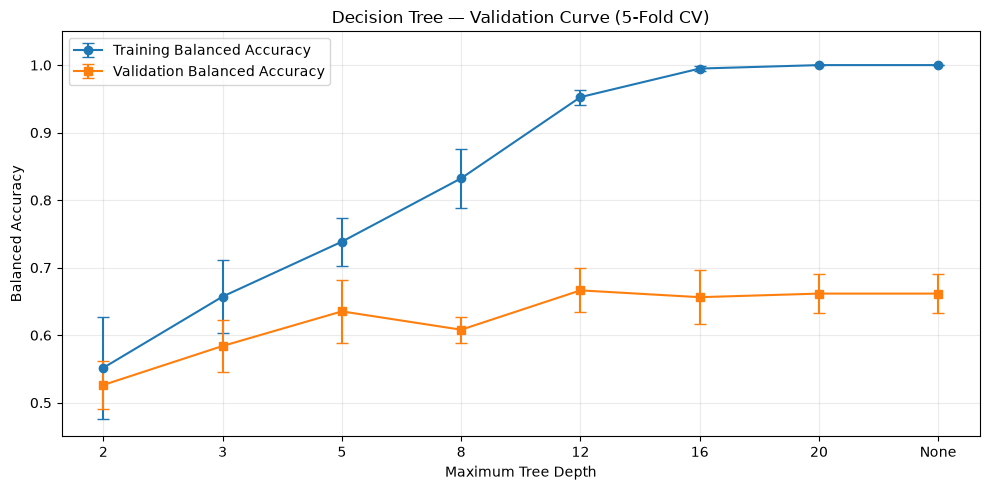

In [17]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

depths = [2, 3, 5, 8, 12, 16, 20, None]

train_means, train_stds = [], []
val_means, val_stds = [], []

for depth in depths:
    train_scores = []
    val_scores = []

    for train_idx, val_idx in folds:
        preprocessor = make_preprocessor()

        X_tr = preprocessor.fit_transform(X_train.iloc[train_idx])
        X_val = preprocessor.transform(X_train.iloc[val_idx])

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = SymbolistClassifier(
            max_depth=depth,
            min_samples_leaf=BEST_PARAMS["Symbolists"]["min_samples_leaf"],
            min_samples_split=BEST_PARAMS["Symbolists"]["min_samples_split"],
            criterion=BEST_PARAMS["Symbolists"]["criterion"],
            ccp_alpha=BEST_PARAMS["Symbolists"]["ccp_alpha"],
            random_state=SEED
        )

        model.fit(X_tr, y_tr)

        train_scores.append(
            balanced_accuracy_score(y_tr, model.predict(X_tr))
        )
        val_scores.append(
            balanced_accuracy_score(y_val, model.predict(X_val))
        )

    train_means.append(np.mean(train_scores))
    train_stds.append(np.std(train_scores, ddof=1))
    val_means.append(np.mean(val_scores))
    val_stds.append(np.std(val_scores, ddof=1))

x = np.arange(len(depths))
labels = [str(d) if d is not None else "None" for d in depths]

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    x, train_means, yerr=train_stds,
    marker="o", capsize=4,
    label="Training Balanced Accuracy"
)

ax.errorbar(
    x, val_means, yerr=val_stds,
    marker="s", capsize=4,
    label="Validation Balanced Accuracy"
)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Maximum Tree Depth")
ax.set_ylabel("Balanced Accuracy")
ax.set_title("Decision Tree — Validation Curve (5-Fold CV)")
ax.set_ylim(0.45, 1.05)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "validation_curve.png", dpi=200, bbox_inches="tight")
plt.show()


**Validation Curve Interpretation**

The Decision Tree exhibits a clear increase in training Balanced Accuracy as tree depth grows, eventually reaching nearly 1.0. However, validation performance peaks at approximately 0.67 around `max_depth=12` and does not improve with further complexity.

The widening training–validation gap indicates overfitting in deeper trees. This supports the selection of `max_depth=12`, although differences between deeper configurations are relatively small compared with cross-validation variability.

## 8. Bayesians — Gaussian Naive Bayes (GNB)

Gaussian Naive Bayes estimates class probabilities using Bayes' theorem, assuming conditional independence between features and Gaussian class-conditional feature distributions.

Hyperparameter optimization focuses on **`var_smoothing`**, which adds a fraction of the largest feature variance to the estimated variances for numerical stability.

The search evaluates **16 values** ranging from `1e-12` to `1.0`, using stratified 5-fold cross-validation (**80 model fits**).

Class priors are estimated from the training data (`priors=None`). Balanced Accuracy is used for hyperparameter selection, while training time is recorded to assess computational efficiency.

All configurations reuse the same fold-specific preprocessing as the other learners.

In [18]:
from time import perf_counter
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

bayesian_param_grid = {
    "var_smoothing": np.concatenate([
        np.logspace(-12, -1, 12),
        [0.2, 0.3, 0.5, 1.0]
    ])
}

bayesian_tuning_results = []
total_start = perf_counter()

for smoothing in bayesian_param_grid["var_smoothing"]:
    scores = []
    times = []

    for X_tr, y_tr, X_val, y_val in prepared_folds:
        model = BayesianClassifier(
            var_smoothing=float(smoothing)
        )

        start = perf_counter()
        model.fit(X_tr, y_tr)
        times.append(perf_counter() - start)

        predictions = model.predict(X_val)
        scores.append(
            balanced_accuracy_score(y_val, predictions)
        )

    bayesian_tuning_results.append({
        "var_smoothing": float(smoothing),
        "mean_balanced_accuracy": np.mean(scores),
        "std_balanced_accuracy": np.std(scores, ddof=1),
        "mean_fit_time": np.mean(times),
        "total_fit_time": np.sum(times)
    })

bayesian_tuning_df = (
    pd.DataFrame(bayesian_tuning_results)
    .sort_values(
        "mean_balanced_accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"Tuning completed in "
    f"{perf_counter()-total_start:.2f}s"
)

display(bayesian_tuning_df)

Tuning completed in 0.06s


,var_smoothing,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,total_fit_time
0,1.000000e-01,0.712045,0.031012,0.000367,0.001836
1,1.000000e-03,0.697759,0.046582,0.000336,0.001678
2,1.000000e-02,0.697479,0.048577,0.000388,0.001942
3,1.000000e-05,0.697199,0.047303,0.000330,0.001651
4,1.000000e-04,0.696919,0.046941,0.000369,0.001845
5,1.000000e-06,0.689916,0.040064,0.000330,0.001651
6,2.000000e-01,0.684314,0.018331,0.000363,0.001816
7,1.000000e-07,0.682353,0.038856,0.000333,0.001663
8,1.000000e-08,0.677591,0.041752,0.000326,0.001628
9,1.000000e-09,0.677031,0.042257,0.000329,0.001644


### Bayesian Hyperparameter Sensitivity Analysis

Gaussian Naive Bayes shows substantial sensitivity to variance smoothing. Balanced Accuracy improves as `var_smoothing` increases from very small values, reaching its highest observed value of approximately **0.712 at 0.1**.

Further increases in smoothing lead to a sharp performance decline, suggesting that excessive variance regularization reduces the model's ability to distinguish between credit-risk classes.

Cross-validation variability also changes across smoothing values, but lower variability does not necessarily correspond to higher predictive performance.

These results demonstrate the importance of tuning variance smoothing rather than relying on the default value (`1e-9`).

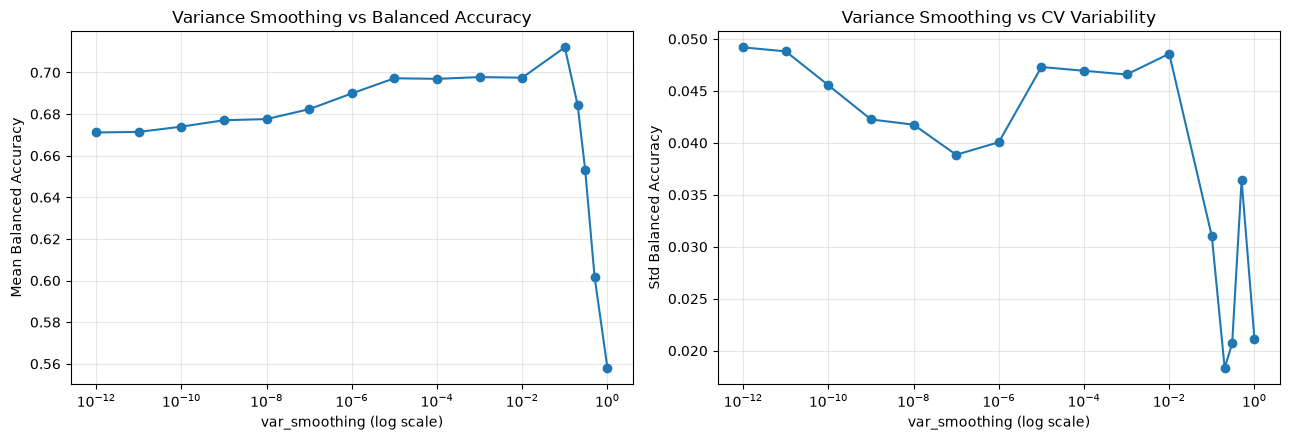

In [19]:

import matplotlib.pyplot as plt

df = bayesian_tuning_df.sort_values("var_smoothing")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(
    df["var_smoothing"],
    df["mean_balanced_accuracy"],
    marker="o"
)
axes[0].set_title("Variance Smoothing vs Balanced Accuracy")
axes[0].set_xlabel("var_smoothing (log scale)")
axes[0].set_ylabel("Mean Balanced Accuracy")
axes[0].grid(alpha=0.3)

axes[1].semilogx(
    df["var_smoothing"],
    df["std_balanced_accuracy"],
    marker="o"
)
axes[1].set_title("Variance Smoothing vs CV Variability")
axes[1].set_xlabel("var_smoothing (log scale)")
axes[1].set_ylabel("Std Balanced Accuracy")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [20]:
best_row = bayesian_tuning_df.iloc[0]

BEST_PARAMS["Bayesians"] = {
    "var_smoothing": float(best_row["var_smoothing"])
}

print("Selected Bayesian parameters:", BEST_PARAMS["Bayesians"])
print(
    f"CV Balanced Accuracy: "
    f"{best_row['mean_balanced_accuracy']:.4f} "
    f"± {best_row['std_balanced_accuracy']:.4f}"
)

Selected Bayesian parameters: {'var_smoothing': 0.1}
CV Balanced Accuracy: 0.7120 ± 0.0310


## 9. Analogizers — K-Nearest Neighbors (KNN)

The Analogizer approach classifies credit applicants by comparing them with previously observed examples. K-Nearest Neighbors (KNN) predicts a class based on the labels of nearby training observations.

Hyperparameters are optimized using stratified 5-fold cross-validation, with Balanced Accuracy as the primary selection metric.

The grid search explores:

- **Number of neighbors (`n_neighbors`):** 3, 5, 7, 11, 15, 21, 31, 41
- **Neighbor weighting (`weights`):** uniform or distance-based
- **Distance metric (`p`):** Manhattan (`p=1`) or Euclidean (`p=2`), using Minkowski distance

The search evaluates **32 configurations across 5 folds (160 model fits)**. All configurations reuse the same fold-specific preprocessing.

KNN is sensitive to feature scaling, distance metrics, and dimensionality. The analysis examines how neighborhood size and weighting affect classification performance and computational cost.

In [21]:
from itertools import product
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

analogizer_param_grid = {
    "n_neighbors": [3, 5, 7, 11, 15, 21, 31, 41],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

combinations = list(product(
    analogizer_param_grid["n_neighbors"],
    analogizer_param_grid["weights"],
    analogizer_param_grid["p"]
))

analogizer_tuning_results = []
total_start = perf_counter()

for n_neighbors, weights, p in combinations:
    scores = []
    fit_times = []
    predict_times = []

    for X_tr, y_tr, X_val, y_val in prepared_folds:
        model = AnalogizerClassifier(
            n_neighbors=n_neighbors,
            weights=weights,
            metric="minkowski",
            p=p
        )

        start = perf_counter()
        model.fit(X_tr, y_tr)
        fit_times.append(perf_counter() - start)

        start = perf_counter()
        predictions = model.predict(X_val)
        predict_times.append(perf_counter() - start)

        scores.append(
            balanced_accuracy_score(y_val, predictions)
        )

    analogizer_tuning_results.append({
        "n_neighbors": n_neighbors,
        "weights": weights,
        "p": p,
        "mean_balanced_accuracy": np.mean(scores),
        "std_balanced_accuracy": np.std(scores, ddof=1),
        "mean_fit_time": np.mean(fit_times),
        "mean_predict_time": np.mean(predict_times),
        "mean_total_time": np.mean(fit_times) + np.mean(predict_times)
    })

analogizer_tuning_df = (
    pd.DataFrame(analogizer_tuning_results)
    .sort_values(
        "mean_balanced_accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"Tuning completed in "
    f"{perf_counter()-total_start:.2f}s"
)

display(analogizer_tuning_df.head(15))

Tuning completed in 0.41s


,n_neighbors,weights,p,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,mean_predict_time,mean_total_time
0,3,distance,2,0.633333,0.011859,0.000188,0.000720,0.000907
1,3,uniform,2,0.632493,0.012628,0.000187,0.001033,0.001220
2,15,distance,1,0.622689,0.036771,0.000172,0.001583,0.001755
3,5,uniform,2,0.619608,0.020574,0.000174,0.000578,0.000752
4,3,uniform,1,0.618207,0.031343,0.000297,0.021041,0.021338
5,3,distance,1,0.618207,0.033564,0.000189,0.001241,0.001430
6,15,uniform,1,0.617647,0.034292,0.000169,0.001735,0.001905
7,5,distance,2,0.616807,0.019896,0.000245,0.001008,0.001253
8,7,distance,2,0.614846,0.025500,0.000172,0.001111,0.001284
9,5,uniform,1,0.614566,0.034753,0.000183,0.001402,0.001585


### Analogizer Hyperparameter Sensitivity Analysis

KNN performance is most sensitive to the number of neighbors. The highest observed cross-validation Balanced Accuracy (approximately **0.633**) is achieved with `k=3`, Euclidean distance (`p=2`), and distance-based weighting.

Increasing the neighborhood size generally reduces performance, suggesting that larger neighborhoods may oversmooth local class distinctions.

Manhattan distance performs slightly better on average across the evaluated configurations, while uniform and distance-based weighting produce similar overall results.

Computational costs remain low for this dataset, with no clear relationship between execution time and predictive performance. However, KNN prediction costs may become more significant as the training dataset grows.

The results highlight the importance of neighborhood size and the sensitivity of distance-based learning to feature representation.

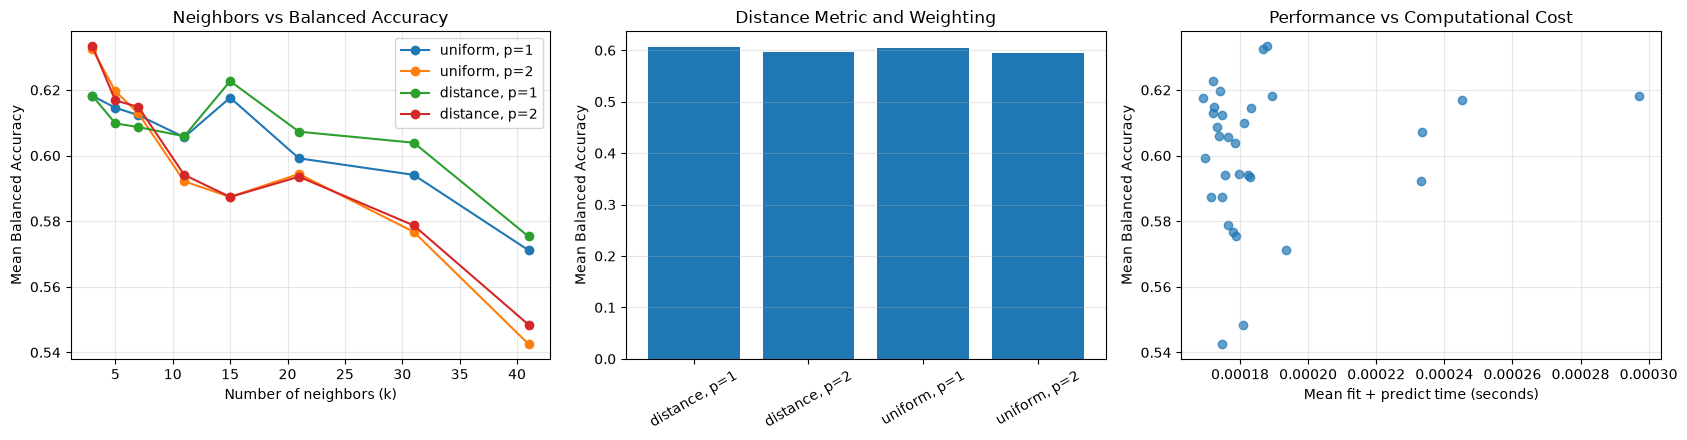

In [22]:

import matplotlib.pyplot as plt

df = analogizer_tuning_df.copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Neighbors vs Balanced Accuracy
for weights in ["uniform", "distance"]:
    for p in [1, 2]:
        subset = df[
            (df["weights"] == weights) &
            (df["p"] == p)
        ].sort_values("n_neighbors")

        axes[0].plot(
            subset["n_neighbors"],
            subset["mean_balanced_accuracy"],
            marker="o",
            label=f"{weights}, p={p}"
        )

axes[0].set_title("Neighbors vs Balanced Accuracy")
axes[0].set_xlabel("Number of neighbors (k)")
axes[0].set_ylabel("Mean Balanced Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Distance Metric and Weighting
grouped = (
    df.groupby(["weights", "p"])["mean_balanced_accuracy"]
    .mean()
)

labels = [
    f"{weights}, p={p}"
    for weights, p in grouped.index
]

axes[1].bar(labels, grouped.values)
axes[1].set_title("Distance Metric and Weighting")
axes[1].set_ylabel("Mean Balanced Accuracy")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.3)

# 3. Performance vs Computational Cost
axes[2].scatter(
    df["mean_fit_time"],
    df["mean_balanced_accuracy"],
    alpha=0.7
)

axes[2].set_title("Performance vs Computational Cost")
axes[2].set_xlabel("Mean fit + predict time (seconds)")
axes[2].set_ylabel("Mean Balanced Accuracy")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [23]:
display(analogizer_tuning_df.head(10))

,n_neighbors,weights,p,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,mean_predict_time,mean_total_time
0,3,distance,2,0.633333,0.011859,0.000188,0.000720,0.000907
1,3,uniform,2,0.632493,0.012628,0.000187,0.001033,0.001220
2,15,distance,1,0.622689,0.036771,0.000172,0.001583,0.001755
3,5,uniform,2,0.619608,0.020574,0.000174,0.000578,0.000752
4,3,uniform,1,0.618207,0.031343,0.000297,0.021041,0.021338
5,3,distance,1,0.618207,0.033564,0.000189,0.001241,0.001430
6,15,uniform,1,0.617647,0.034292,0.000169,0.001735,0.001905
7,5,distance,2,0.616807,0.019896,0.000245,0.001008,0.001253
8,7,distance,2,0.614846,0.025500,0.000172,0.001111,0.001284
9,5,uniform,1,0.614566,0.034753,0.000183,0.001402,0.001585


In [24]:
best_row = analogizer_tuning_df.iloc[0]

BEST_PARAMS["Analogizers"] = {
    "n_neighbors": int(best_row["n_neighbors"]),
    "weights": str(best_row["weights"]),
    "metric": "minkowski",
    "p": int(best_row["p"])
}

print("Selected Analogizer parameters:")
print(BEST_PARAMS["Analogizers"])

print(
    f"CV Balanced Accuracy: "
    f"{best_row['mean_balanced_accuracy']:.4f} "
    f"± {best_row['std_balanced_accuracy']:.4f}"
)

Selected Analogizer parameters:
{'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 2}
CV Balanced Accuracy: 0.6333 ± 0.0119


## 10. Connectionists — Multi-Layer Perceptron (MLP)

The Connectionist approach uses a Multi-Layer Perceptron (MLP) to learn nonlinear relationships through interconnected artificial neurons. Model weights are optimized using backpropagation and the Adam optimizer.

Hyperparameters are selected using **stratified 5-fold cross-validation**, with Balanced Accuracy as the primary metric.

The grid search explores:

- **Network architecture (`hidden_layer_sizes`):** (16,) and (32, 16)
- **L2 regularization (`alpha`):** 0.001 and 0.1
- **Initial learning rate (`learning_rate_init`):** 0.001 and 0.01
- **Activation function (`activation`):** ReLU and tanh

The optimizer (`adam`), maximum iterations (`300`), early stopping (`True`), and random seed (`42`) remain fixed.

The search evaluates **16 configurations across 5 folds (80 model fits)**, recording predictive performance, cross-validation variability, and training time.

Given the limited dataset size, the analysis focuses on the trade-off between model complexity, regularization, and generalization rather than maximizing network size.

In [25]:
from itertools import product
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

connectionist_param_grid = {
    "hidden_layer_sizes": [(16,), (32, 16)],
    "alpha": [0.001, 0.1],
    "learning_rate_init": [0.001, 0.01],
    "activation": ["relu", "tanh"]
}

combinations = list(product(
    connectionist_param_grid["hidden_layer_sizes"],
    connectionist_param_grid["alpha"],
    connectionist_param_grid["learning_rate_init"],
    connectionist_param_grid["activation"]
))

connectionist_tuning_results = []
total_start = perf_counter()

for i, (layers, alpha, lr, activation) in enumerate(
    combinations, start=1
):
    scores = []
    times = []

    for X_tr, y_tr, X_val, y_val in prepared_folds:
        model = ConnectionistClassifier(
            hidden_layer_sizes=layers,
            activation=activation,
            solver="adam",
            alpha=alpha,
            learning_rate_init=lr,
            max_iter=300,
            early_stopping=True,
            random_state=SEED
        )

        start = perf_counter()
        model.fit(X_tr, y_tr)
        times.append(perf_counter() - start)

        predictions = model.predict(X_val)

        scores.append(
            balanced_accuracy_score(y_val, predictions)
        )

    connectionist_tuning_results.append({
        "hidden_layer_sizes": layers,
        "alpha": alpha,
        "learning_rate_init": lr,
        "activation": activation,
        "mean_balanced_accuracy": np.mean(scores),
        "std_balanced_accuracy": np.std(scores, ddof=1),
        "mean_fit_time": np.mean(times),
        "total_fit_time": np.sum(times)
    })

    print(
        f"[{i}/{len(combinations)}] "
        f"layers={layers}, alpha={alpha}, "
        f"lr={lr}, activation={activation} | "
        f"BA={np.mean(scores):.4f} | "
        f"elapsed={perf_counter()-total_start:.1f}s",
        flush=True
    )

connectionist_tuning_df = (
    pd.DataFrame(connectionist_tuning_results)
    .sort_values(
        "mean_balanced_accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"\nTotal tuning time: "
    f"{perf_counter()-total_start:.2f}s"
)

display(connectionist_tuning_df.head(16))

[1/16] layers=(16,), alpha=0.001, lr=0.001, activation=relu | BA=0.5199 | elapsed=0.1s
[2/16] layers=(16,), alpha=0.001, lr=0.001, activation=tanh | BA=0.5675 | elapsed=0.2s
[3/16] layers=(16,), alpha=0.001, lr=0.01, activation=relu | BA=0.6692 | elapsed=0.3s
[4/16] layers=(16,), alpha=0.001, lr=0.01, activation=tanh | BA=0.6263 | elapsed=0.3s
[5/16] layers=(16,), alpha=0.1, lr=0.001, activation=relu | BA=0.5204 | elapsed=0.4s
[6/16] layers=(16,), alpha=0.1, lr=0.001, activation=tanh | BA=0.5510 | elapsed=0.5s
[7/16] layers=(16,), alpha=0.1, lr=0.01, activation=relu | BA=0.6630 | elapsed=0.6s
[8/16] layers=(16,), alpha=0.1, lr=0.01, activation=tanh | BA=0.6479 | elapsed=0.6s
[9/16] layers=(32, 16), alpha=0.001, lr=0.001, activation=relu | BA=0.5429 | elapsed=0.8s
[10/16] layers=(32, 16), alpha=0.001, lr=0.001, activation=tanh | BA=0.6084 | elapsed=0.9s
[11/16] layers=(32, 16), alpha=0.001, lr=0.01, activation=relu | BA=0.6521 | elapsed=1.0s
[12/16] layers=(32, 16), alpha=0.001, lr=0.01

,hidden_layer_sizes,alpha,learning_rate_init,activation,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,total_fit_time
0,"(16,)",0.001,0.010,relu,0.669188,0.049985,0.013889,0.069443
1,"(16,)",0.100,0.010,relu,0.663025,0.035907,0.011225,0.056123
2,"(32, 16)",0.100,0.010,relu,0.656583,0.032066,0.018918,0.094588
3,"(32, 16)",0.001,0.010,relu,0.652101,0.027096,0.018197,0.090983
4,"(16,)",0.100,0.010,tanh,0.647899,0.101893,0.010395,0.051977
5,"(32, 16)",0.001,0.010,tanh,0.636415,0.066069,0.021355,0.106773
6,"(16,)",0.001,0.010,tanh,0.626331,0.066297,0.011013,0.055065
7,"(32, 16)",0.100,0.010,tanh,0.617927,0.058459,0.013644,0.068221
8,"(32, 16)",0.100,0.001,tanh,0.614286,0.060554,0.024139,0.120693
9,"(32, 16)",0.001,0.001,tanh,0.608403,0.052419,0.022585,0.112925


### Connectionist Hyperparameter Sensitivity Analysis

MLP performance is particularly sensitive to the initial learning rate. Increasing `learning_rate_init` from 0.001 to 0.01 substantially improves mean cross-validation Balanced Accuracy, especially with ReLU activation.

Network architecture interacts with the activation function: the larger architecture improves average performance with tanh, while ReLU shows little difference between the tested architectures when averaged across other settings.

Stronger L2 regularization slightly reduces average performance, suggesting no clear benefit from increasing `alpha` within the evaluated range.

Training time does not consistently predict model quality. Overall, the results highlight the importance of optimization settings and hyperparameter interactions, particularly for neural networks trained on relatively small datasets.

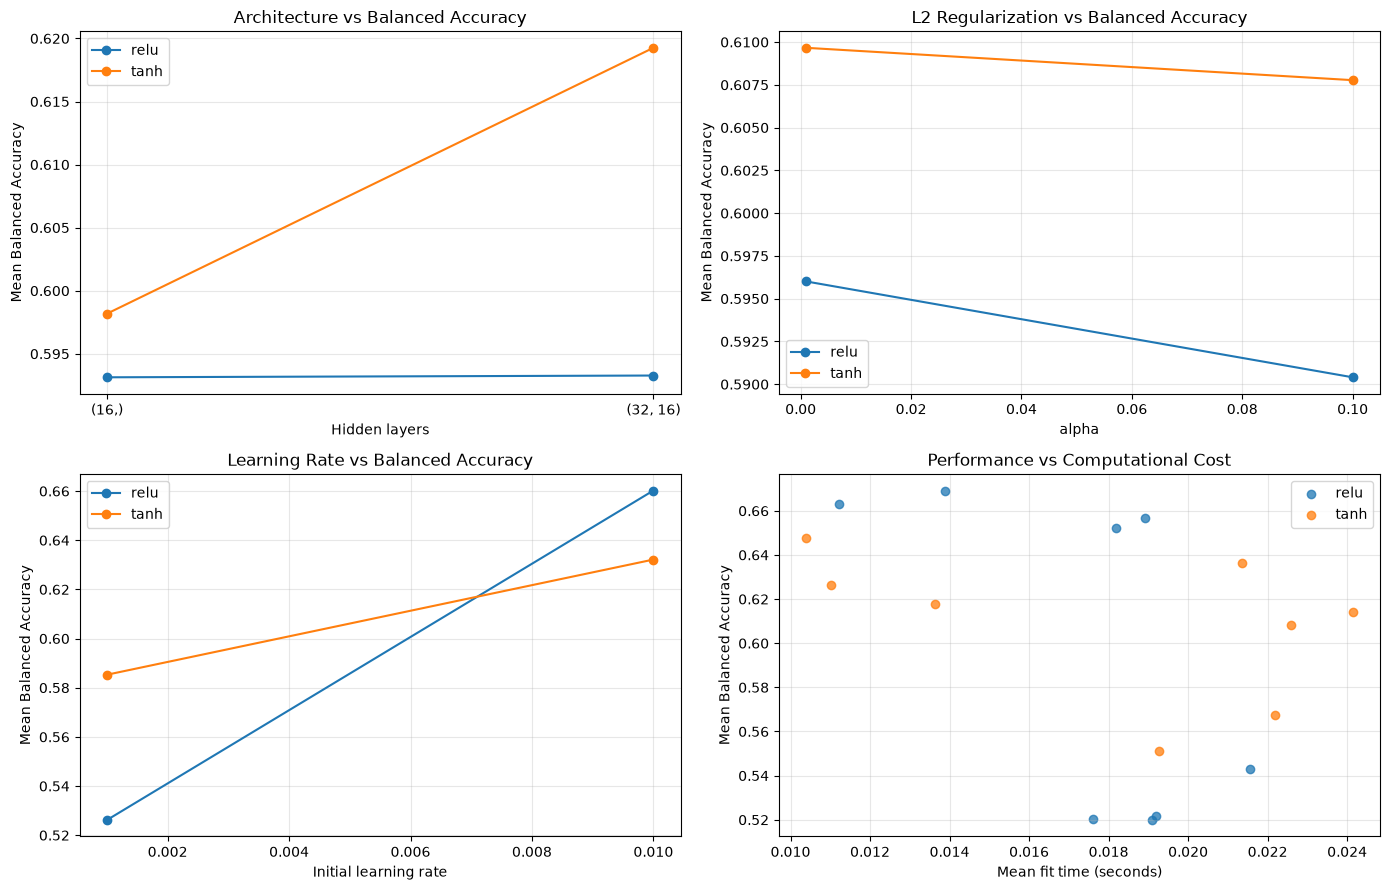

In [26]:

import matplotlib.pyplot as plt

df = connectionist_tuning_df.copy()
df["architecture"] = df["hidden_layer_sizes"].astype(str)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Architecture vs Balanced Accuracy
for activation in ["relu", "tanh"]:
    subset = df[df["activation"] == activation]
    grouped = subset.groupby("architecture")["mean_balanced_accuracy"].mean()

    axes[0, 0].plot(
        grouped.index,
        grouped.values,
        marker="o",
        label=activation
    )

axes[0, 0].set_title("Architecture vs Balanced Accuracy")
axes[0, 0].set_xlabel("Hidden layers")
axes[0, 0].set_ylabel("Mean Balanced Accuracy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Regularization vs Balanced Accuracy
for activation in ["relu", "tanh"]:
    subset = df[df["activation"] == activation]
    grouped = subset.groupby("alpha")["mean_balanced_accuracy"].mean()

    axes[0, 1].plot(
        grouped.index,
        grouped.values,
        marker="o",
        label=activation
    )

axes[0, 1].set_title("L2 Regularization vs Balanced Accuracy")
axes[0, 1].set_xlabel("alpha")
axes[0, 1].set_ylabel("Mean Balanced Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Learning Rate vs Balanced Accuracy
for activation in ["relu", "tanh"]:
    subset = df[df["activation"] == activation]
    grouped = subset.groupby("learning_rate_init")["mean_balanced_accuracy"].mean()

    axes[1, 0].plot(
        grouped.index,
        grouped.values,
        marker="o",
        label=activation
    )

axes[1, 0].set_title("Learning Rate vs Balanced Accuracy")
axes[1, 0].set_xlabel("Initial learning rate")
axes[1, 0].set_ylabel("Mean Balanced Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Performance vs Computational Cost
for activation in ["relu", "tanh"]:
    subset = df[df["activation"] == activation]

    axes[1, 1].scatter(
        subset["mean_fit_time"],
        subset["mean_balanced_accuracy"],
        label=activation,
        alpha=0.75
    )

axes[1, 1].set_title("Performance vs Computational Cost")
axes[1, 1].set_xlabel("Mean fit time (seconds)")
axes[1, 1].set_ylabel("Mean Balanced Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:
display(connectionist_tuning_df.head(10))

,hidden_layer_sizes,alpha,learning_rate_init,activation,mean_balanced_accuracy,std_balanced_accuracy,mean_fit_time,total_fit_time
0,"(16,)",0.001,0.010,relu,0.669188,0.049985,0.013889,0.069443
1,"(16,)",0.100,0.010,relu,0.663025,0.035907,0.011225,0.056123
2,"(32, 16)",0.100,0.010,relu,0.656583,0.032066,0.018918,0.094588
3,"(32, 16)",0.001,0.010,relu,0.652101,0.027096,0.018197,0.090983
4,"(16,)",0.100,0.010,tanh,0.647899,0.101893,0.010395,0.051977
5,"(32, 16)",0.001,0.010,tanh,0.636415,0.066069,0.021355,0.106773
6,"(16,)",0.001,0.010,tanh,0.626331,0.066297,0.011013,0.055065
7,"(32, 16)",0.100,0.010,tanh,0.617927,0.058459,0.013644,0.068221
8,"(32, 16)",0.100,0.001,tanh,0.614286,0.060554,0.024139,0.120693
9,"(32, 16)",0.001,0.001,tanh,0.608403,0.052419,0.022585,0.112925


In [28]:

best_row = connectionist_tuning_df.iloc[0]

BEST_PARAMS["Connectionists"] = {
    "hidden_layer_sizes": tuple(best_row["hidden_layer_sizes"]),
    "alpha": float(best_row["alpha"]),
    "learning_rate_init": float(best_row["learning_rate_init"]),
    "activation": str(best_row["activation"]),
    "solver": "adam",
    "max_iter": 300,
    "early_stopping": True,
    "random_state": SEED
}

print("Selected Connectionist parameters:")
print(BEST_PARAMS["Connectionists"])

print(
    f"CV Balanced Accuracy: "
    f"{best_row['mean_balanced_accuracy']:.4f} "
    f"± {best_row['std_balanced_accuracy']:.4f}"
)

Selected Connectionist parameters:
{'hidden_layer_sizes': (16,), 'alpha': 0.001, 'learning_rate_init': 0.01, 'activation': 'relu', 'solver': 'adam', 'max_iter': 300, 'early_stopping': True, 'random_state': 42}
CV Balanced Accuracy: 0.6692 ± 0.0500


,Learner,Mean CV Balanced Accuracy,Std CV Balanced Accuracy
0,Evolutionaries,0.7120,0.0307
1,Bayesians,0.7120,0.0310
2,Connectionists,0.6692,0.0500
3,Symbolists,0.6664,0.0326
4,Analogizers,0.6333,0.0119
5,Baseline (majority),0.5000,0.0000


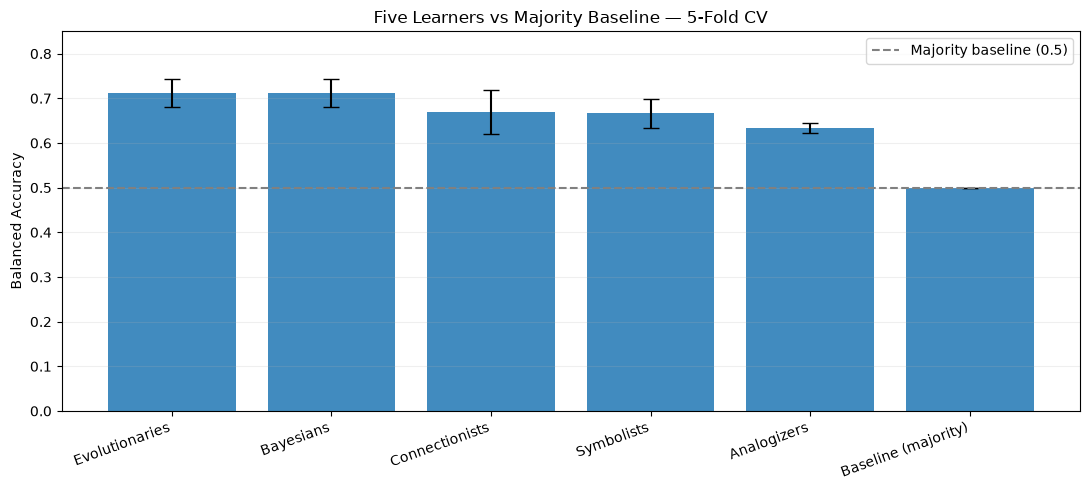

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Best configuration for each learner, selected by 5-fold CV
tuning_tables = {
    "Evolutionaries": tuning_df,
    "Symbolists": symbolist_tuning_df,
    "Bayesians": bayesian_tuning_df,
    "Analogizers": analogizer_tuning_df,
    "Connectionists": connectionist_tuning_df,
}

cv_comparison = []

for name, df in tuning_tables.items():
    best = df.sort_values(
        "mean_balanced_accuracy", ascending=False
    ).iloc[0]

    cv_comparison.append({
        "Learner": name,
        "Mean CV Balanced Accuracy": best["mean_balanced_accuracy"],
        "Std CV Balanced Accuracy": best["std_balanced_accuracy"]
    })

# Majority-class baseline: Balanced Accuracy = 0.5
cv_comparison.append({
    "Learner": "Baseline (majority)",
    "Mean CV Balanced Accuracy": 0.5,
    "Std CV Balanced Accuracy": 0.0
})

cv_comparison_df = (
    pd.DataFrame(cv_comparison)
    .sort_values("Mean CV Balanced Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(cv_comparison_df.round(4))

# Plot CV mean +/- standard deviation
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(cv_comparison_df))

ax.bar(
    x,
    cv_comparison_df["Mean CV Balanced Accuracy"],
    yerr=cv_comparison_df["Std CV Balanced Accuracy"],
    capsize=6,
    alpha=0.85
)

ax.set_xticks(x)
ax.set_xticklabels(
    cv_comparison_df["Learner"],
    rotation=20,
    ha="right"
)

ax.set_ylabel("Balanced Accuracy")
ax.set_title(
    "Five Learners vs Majority Baseline — 5-Fold CV"
)
ax.set_ylim(0, 0.85)
ax.axhline(
    0.5,
    linestyle="--",
    color="gray",
    label="Majority baseline (0.5)"
)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cv_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


### Cross-Validation Comparison

The chart compares the five learning paradigms using the mean Balanced Accuracy and standard deviation across five stratified cross-validation folds, based on their selected hyperparameter configurations.

Error bars represent variability between folds rather than confidence intervals. The majority-class baseline achieves a Balanced Accuracy of 0.50.

This comparison highlights both predictive performance and stability across validation folds. Final holdout performance is evaluated separately in the following section.

## 11. Final Model Selection and Fitting

The best hyperparameters for all five learners were selected using stratified 5-fold cross-validation on the development dataset.

After hyperparameter selection, each learner is refitted using all **850 development observations**, with a shared preprocessing strategy fitted exclusively on development data.

The remaining **150 holdout observations** are reserved for final performance evaluation and are not used for model fitting or hyperparameter optimization.

The final comparison evaluates predictive performance, class-specific errors, and computational efficiency across the five learning paradigms.

In [30]:
LEARNERS = [
    "Evolutionaries",
    "Symbolists",
    "Bayesians",
    "Analogizers",
    "Connectionists"
]

assert all(
    name in BEST_PARAMS and BEST_PARAMS[name]
    for name in LEARNERS
), "Missing selected hyperparameters"

for name in LEARNERS:
    print(f"{name}: {BEST_PARAMS[name]}")

Evolutionaries: {'n_iter': 200, 'n_pop': 80, 'weight_bound': 2.0, 'bias_bound': 2.5, 'class_0_weight': 5.0, 'random_state': 42}
Symbolists: {'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 2, 'criterion': 'gini', 'ccp_alpha': 0.0, 'random_state': 42}
Bayesians: {'var_smoothing': 0.1}
Analogizers: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 2}
Connectionists: {'hidden_layer_sizes': (16,), 'alpha': 0.001, 'learning_rate_init': 0.01, 'activation': 'relu', 'solver': 'adam', 'max_iter': 300, 'early_stopping': True, 'random_state': 42}


### Final Model Fitting

All five learners are refitted on the complete development dataset (850 observations) using the hyperparameters selected through cross-validation.

A shared preprocessor is fitted exclusively on development data. The resulting transformed features are used to train each model under identical experimental conditions.

Training times are recorded separately for each learner. The fitted models are retained for subsequent evaluation on the 150-observation holdout set.

In [31]:

from time import perf_counter
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Final models with selected hyperparameters
final_estimators = {
    "Symbolists": SymbolistClassifier(
        **BEST_PARAMS["Symbolists"]
    ),
    "Bayesians": BayesianClassifier(
        **BEST_PARAMS["Bayesians"]
    ),
    "Analogizers": AnalogizerClassifier(
        **BEST_PARAMS["Analogizers"]
    ),
    "Connectionists": ConnectionistClassifier(
        **BEST_PARAMS["Connectionists"]
    ),
    "Evolutionaries": EvolutionaryClassifier(
        **BEST_PARAMS["Evolutionaries"]
    )
}


# Preprocessing: fit only on development data
final_preprocessor = make_preprocessor()

X_dev_processed = final_preprocessor.fit_transform(X_train)
X_test_processed = final_preprocessor.transform(X_final_test)

# Train and retain the five final models
FINAL_MODELS = {}
final_training_times = {}

for name, model in final_estimators.items():
    start = perf_counter()

    model.fit(X_dev_processed, y_train)

    elapsed = perf_counter() - start

    FINAL_MODELS[name] = model
    final_training_times[name] = elapsed

    print(f"{name}: trained in {elapsed:.3f}s")

print("\nAll five models trained successfully.")


Symbolists: trained in 0.002s
Bayesians: trained in 0.001s
Analogizers: trained in 0.000s
Connectionists: trained in 0.015s
Evolutionaries: trained in 0.709s

All five models trained successfully.


### Final Model Comparison — Discussion

All five learning paradigms outperform the majority-class baseline in Balanced Accuracy, demonstrating that they learn useful patterns beyond the class distribution.

Evolutionaries achieves the highest Balanced Accuracy (0.7222) and Bad Credit recall (91.1%), identifying 41 of 45 risky applicants. However, this comes at the cost of 49 false rejections among 105 Good applicants. This trade-off is influenced by its cost-sensitive objective (`class_0_weight=5.0`).

Bayesians achieves the highest overall Accuracy (74.0%) and a more balanced error profile, while Symbolists, Connectionists, and Analogizers show lower sensitivity to Bad Credit.

The majority baseline achieves 70% Accuracy but 50% Balanced Accuracy and 0% Bad Credit recall, confirming that Accuracy alone is insufficient for evaluating this imbalanced classification problem.

These results illustrate that model selection depends not only on predictive performance but also on the relative costs of missed risky applicants and false rejections.

,Learner,Accuracy,Balanced Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),Training Time (s)
0,Evolutionaries,0.6467,0.7222,0.4556,0.9111,0.6074,0.7087
1,Bayesians,0.7400,0.6810,0.5714,0.5333,0.5517,0.0009
2,Symbolists,0.7000,0.6587,0.5000,0.5556,0.5263,0.0024
3,Connectionists,0.7200,0.6349,0.5429,0.4222,0.4750,0.0147
4,Analogizers,0.7000,0.6079,0.5000,0.3778,0.4304,0.0003
5,Baseline (majority),0.7000,0.5000,0.0000,0.0000,0.0000,0.0003


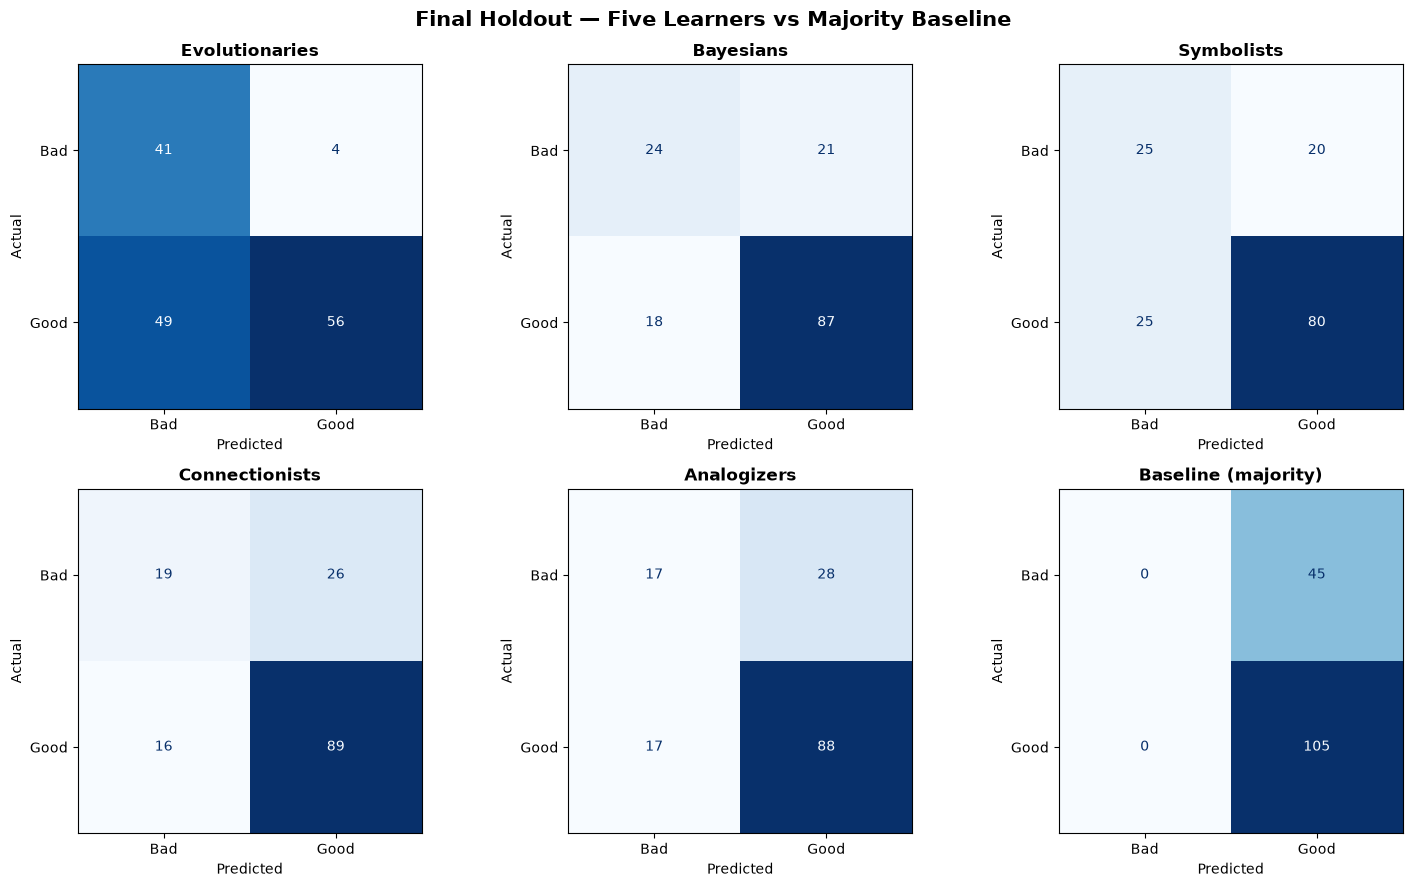

In [32]:

from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# 1. Add majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

start = perf_counter()
baseline.fit(X_dev_processed, y_train)
baseline_time = perf_counter() - start

# 2. Evaluate all five learners + baseline
all_models = {
    **FINAL_MODELS,
    "Baseline (majority)": baseline
}

final_results = []
FINAL_PREDICTIONS = {}

for name, model in all_models.items():
    predictions = model.predict(X_test_processed)
    FINAL_PREDICTIONS[name] = predictions

    final_results.append({
        "Learner": name,
        "Accuracy": accuracy_score(y_final_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_final_test, predictions
        ),
        "Precision (Bad)": precision_score(
            y_final_test, predictions,
            pos_label=0, zero_division=0
        ),
        "Recall (Bad)": recall_score(
            y_final_test, predictions,
            pos_label=0, zero_division=0
        ),
        "F1 (Bad)": f1_score(
            y_final_test, predictions,
            pos_label=0, zero_division=0
        ),
        "Training Time (s)": (
            baseline_time if name == "Baseline (majority)"
            else final_training_times[name]
        )
    })

# 3. Final comparison table
final_results_df = (
    pd.DataFrame(final_results)
    .sort_values("Balanced Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(final_results_df.round(4))

# 4. Confusion matrices for all six models
model_names = final_results_df["Learner"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, name in zip(axes, model_names):
    ConfusionMatrixDisplay.from_predictions(
        y_final_test,
        FINAL_PREDICTIONS[name],
        labels=[0, 1],
        display_labels=["Bad", "Good"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

fig.suptitle(
    "Final Holdout — Five Learners vs Majority Baseline",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()


**Figure — Final Holdout Performance Comparison**

The chart compares Accuracy, Balanced Accuracy, and Bad Credit Recall across five learning paradigms and the majority-class baseline.

Evolutionaries achieves the highest Balanced Accuracy (0.722) and Bad Credit Recall (0.911), while Bayesians achieves the highest overall Accuracy (0.740). The majority baseline reaches 70% Accuracy but fails to identify any Bad Credit applicants (Recall = 0).

These results demonstrate why Balanced Accuracy is more informative than overall Accuracy for this imbalanced dataset and highlight the trade-off between detecting risky applicants and incorrectly rejecting creditworthy ones.

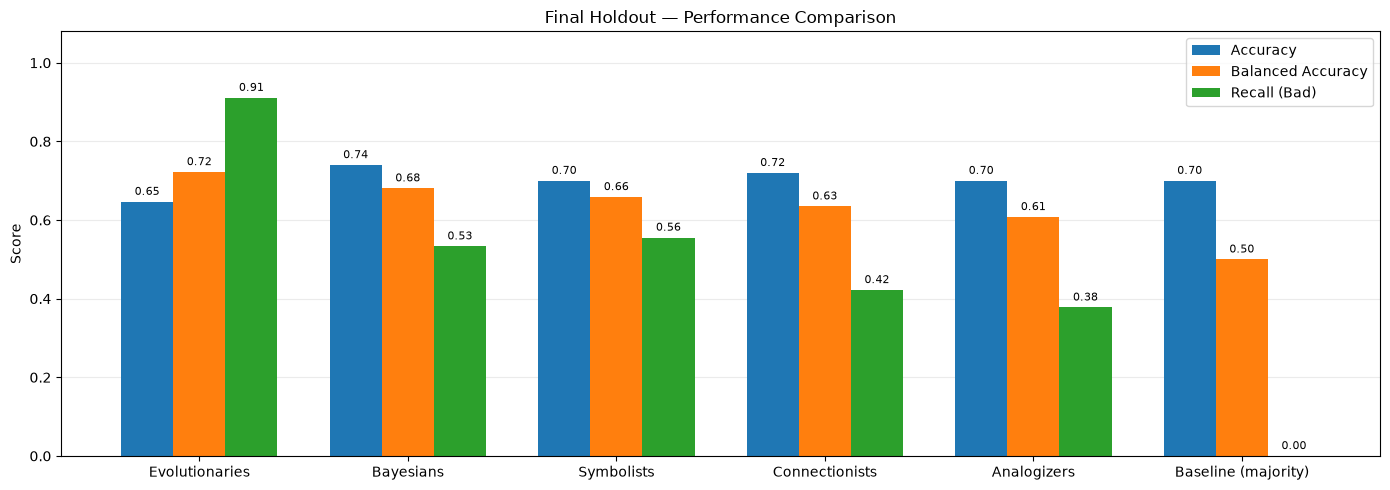

In [33]:

import numpy as np
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Recall (Bad)"
]

# Includes all five learners + majority baseline
df_plot = final_results_df.set_index("Learner")

x = np.arange(len(df_plot))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 5))

for i, metric in enumerate(metrics):
    bars = ax.bar(
        x + (i - 1) * width,
        df_plot[metric],
        width,
        label=metric
    )
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(df_plot.index)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.set_title("Final Holdout — Performance Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Figure — Credit Risk Error Trade-off**

The chart compares two types of classification errors: missed risky applicants (Bad predicted as Good) and incorrectly rejected creditworthy applicants (Good predicted as Bad).

Evolutionaries misses only 4 of 45 risky applicants but incorrectly rejects 49 of 105 Good applicants. The majority baseline misses all 45 risky applicants while rejecting none of the Good applicants.

The results demonstrate that reducing one type of error can increase the other. The preferred model therefore depends on the relative financial costs of these errors.

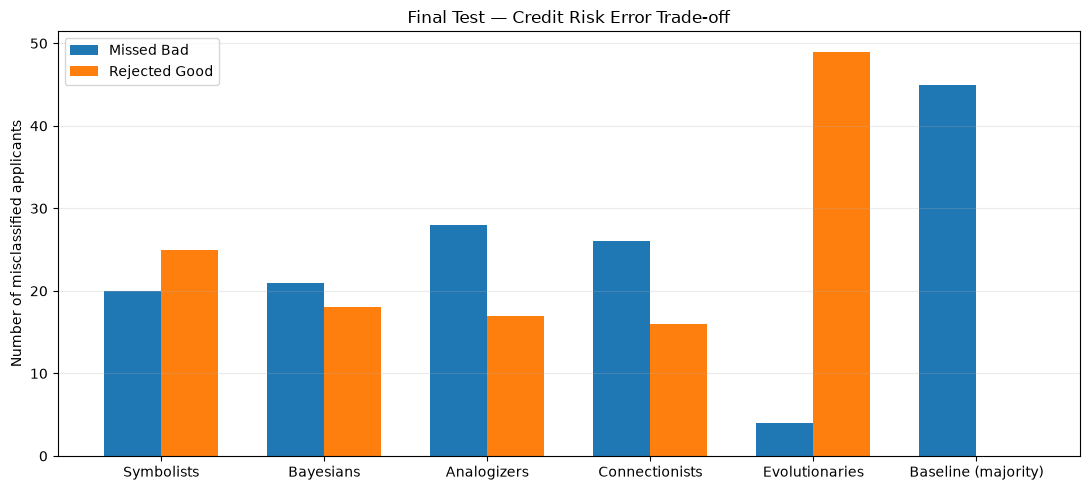

,Learner,Missed Bad,Rejected Good
0,Symbolists,20,25
1,Bayesians,21,18
2,Analogizers,28,17
3,Connectionists,26,16
4,Evolutionaries,4,49
5,Baseline (majority),45,0


In [34]:

from sklearn.metrics import confusion_matrix

error_data = []

for name, predictions in FINAL_PREDICTIONS.items():
    cm = confusion_matrix(
        y_final_test,
        predictions,
        labels=[0, 1]
    )

    error_data.append({
        "Learner": name,
        "Missed Bad": int(cm[0, 1]),
        "Rejected Good": int(cm[1, 0])
    })

error_df = pd.DataFrame(error_data)

x = np.arange(len(error_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    x - width / 2,
    error_df["Missed Bad"],
    width,
    label="Missed Bad"
)

ax.bar(
    x + width / 2,
    error_df["Rejected Good"],
    width,
    label="Rejected Good"
)

ax.set_xticks(x)
ax.set_xticklabels(error_df["Learner"])
ax.set_ylabel("Number of misclassified applicants")
ax.set_title("Final Test — Credit Risk Error Trade-off")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_tradeoffs.png", dpi=200, bbox_inches="tight")
plt.show()

display(error_df)


### Evolutionaries — Decision Threshold Sensitivity Analysis

The Evolutionary classifier is examined across different decision thresholds to investigate the trade-off between detecting high-risk applicants and incorrectly rejecting creditworthy applicants.

Out-of-fold predictions from stratified 5-fold cross-validation on the development set are used to avoid optimizing the threshold on the final holdout.

We examine Recall (Bad), Precision (Bad), Balanced Accuracy, and a cost-sensitive metric assuming that accepting a bad applicant is five times more costly than rejecting a good applicant.

The 5:1 cost ratio is treated as an experimental assumption for sensitivity analysis.

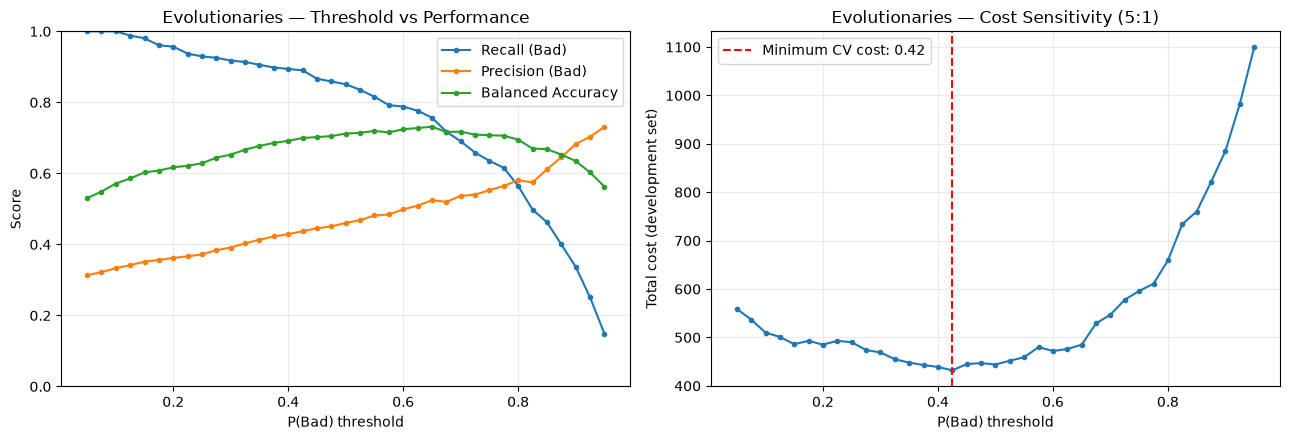

Minimum-cost CV threshold: 0.425


,Threshold,Recall (Bad),Precision (Bad),Balanced Accuracy,Cost (5:1)
0,0.050,1.0000,0.3133,0.5303,559
1,0.075,1.0000,0.3220,0.5487,537
2,0.100,1.0000,0.3333,0.5714,510
3,0.125,0.9882,0.3415,0.5857,501
4,0.150,0.9804,0.3516,0.6028,486
5,0.175,0.9608,0.3561,0.6081,493
6,0.200,0.9569,0.3620,0.6171,485
7,0.225,0.9373,0.3666,0.6216,493
8,0.250,0.9294,0.3721,0.6286,490
9,0.275,0.9255,0.3837,0.6443,474


In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Out-of-fold probabilities on development data
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

oof_bad_proba = np.zeros(len(y_train))
y_dev = np.asarray(y_train)

for train_idx, val_idx in cv.split(X_train, y_dev):
    X_tr = X_train.iloc[train_idx]
    X_val = X_train.iloc[val_idx]

    preprocessor = make_preprocessor()
    X_tr_p = preprocessor.fit_transform(X_tr)
    X_val_p = preprocessor.transform(X_val)

    model = EvolutionaryClassifier(
        **BEST_PARAMS["Evolutionaries"]
    )
    model.fit(X_tr_p, y_dev[train_idx])

    probabilities = model.predict_proba(X_val_p)
    bad_col = np.where(model.classes_ == 0)[0][0]
    oof_bad_proba[val_idx] = probabilities[:, bad_col]

# Threshold sensitivity
thresholds = np.linspace(0.05, 0.95, 37)
rows = []

for threshold in thresholds:
    predictions = np.where(
        oof_bad_proba >= threshold, 0, 1
    )

    cm = confusion_matrix(
        y_dev, predictions, labels=[0, 1]
    )

    missed_bad = int(cm[0, 1])
    rejected_good = int(cm[1, 0])

    rows.append({
        "Threshold": threshold,
        "Recall (Bad)": recall_score(
            y_dev, predictions, pos_label=0,
            zero_division=0
        ),
        "Precision (Bad)": precision_score(
            y_dev, predictions, pos_label=0,
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_dev, predictions
        ),
        "Cost (5:1)": 5 * missed_bad + rejected_good
    })

threshold_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for metric in [
    "Recall (Bad)",
    "Precision (Bad)",
    "Balanced Accuracy"
]:
    axes[0].plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o", markersize=3, label=metric
    )

axes[0].set(
    title="Evolutionaries — Threshold vs Performance",
    xlabel="P(Bad) threshold",
    ylabel="Score",
    ylim=(0, 1)
)
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    threshold_df["Threshold"],
    threshold_df["Cost (5:1)"],
    marker="o", markersize=3
)

best_idx = threshold_df["Cost (5:1)"].idxmin()
best_threshold = threshold_df.loc[best_idx, "Threshold"]

axes[1].axvline(
    best_threshold, color="red", linestyle="--",
    label=f"Minimum CV cost: {best_threshold:.2f}"
)
axes[1].set(
    title="Evolutionaries — Cost Sensitivity (5:1)",
    xlabel="P(Bad) threshold",
    ylabel="Total cost (development set)"
)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Minimum-cost CV threshold: {best_threshold:.3f}")
display(threshold_df.round(4))


### Threshold Sensitivity — Interpretation

The Evolutionary classifier demonstrates a trade-off between detecting high-risk applicants and incorrectly rejecting creditworthy applicants.

Using out-of-fold predictions from the development set, the lowest observed misclassification cost under the 5:1 cost ratio occurs at a threshold of **0.425**.

The analysis shows that lowering the threshold for predicting Good Credit generally increases the number of high-risk applicants incorrectly approved, while raising it reduces missed Bad Credit cases at the expense of rejecting more creditworthy applicants.

The threshold that minimizes misclassification cost does not necessarily maximize Balanced Accuracy, demonstrating the importance of aligning decision thresholds with business objectives.

This exploratory threshold analysis was performed exclusively on development data and was not used to modify the final holdout evaluation.